# 2. Modelar, evaluar y pronosticar 28 días

**Objetivo:** pronosticar cuántas órdenes recibirá Olist cada día durante las cuatro semanas siguientes a un cierre de domingo, comparar modelos contra referencias simples y cuantificar la incertidumbre.

Secuencia: ejemplos supervisados sin fuga → estrategia multi-paso → candidatos → selección temporal → calibración de incertidumbre en una etapa reservada → evaluación retrospectiva → pronóstico final.

Cada tabla y figura se exporta a `resultados/` o `documentacion/figuras/`. Las funciones están en `src/modelos.py` y `src/evaluacion.py`; el notebook explica qué hacen y muestra sus entradas y salidas. Los datos de prueba ya eran conocidos en este ejercicio: el protocolo respeta el tiempo, pero **no constituye una nueva evaluación ciega**.

## 0. Lo que este notebook hereda de la exploración

[B_series_01_exploracion](B_series_01_exploracion.ipynb) fijó la forma de los modelos con datos anteriores al primer origen de selección. Aquí no se vuelve a decidir nada de eso: se aplica y se evalúa.

| Evidencia en 01 | Decisión | Cómo se aplica aquí |
|---|---|---|
| Crecimiento en 2017 y meseta en 2018 (§2.1) | No extrapolar una tendencia fija | SARIMAX sin deriva; ETS con tendencia amortiguada; LightGBM con variantes de objetivo relativo al nivel reciente |
| Amplitud semanal proporcional al nivel (§2.3) | Modelar en `log1p(y)` | SARIMAX y ETS sobre `log1p`; objetivo relativo de LightGBM en log |
| Nivel no estacionario, primera diferencia estacionaria (§2.5) | `d = 1` | Errores ARIMA(1,1,1) |
| Semana estable; MA estacional cercano a −1; ACF sin picos semanales tras descontar los días (§2.2, §2.6, §2.7) | Semana determinística | Seis indicadores de día en SARIMAX; `dia_semana` en LightGBM |
| Picos de la ACF en múltiplos de 7 (§2.6) | Usar el mismo día de semanas anteriores | `lag_6`, `lag_13`, `lag_27`, `ultimo_mismo_dia`, `media_4_mismo_dia` |
| Black Friday, días posteriores, fin de año, festivos y Carnaval: previsibles (§3.3) | **Modelar** | Indicadores `black_friday`, `post_black_friday`, `fin_anio`, `festivo`, `carnaval` |
| Huelga de camioneros: imprevisible (§3.3) | **Marcar** | Sin indicador futuro; dentro de las métricas; su error se informa aparte (§15) |
| Caída previa a Navidad vista solo en datos de selección (§3.3) | Limitación, sin cambio | Se mide su error en §15 |

El protocolo es el de 01 §1: 30 emisiones de selección, 12 de calibración y 5 de prueba, cada una al cierre de un domingo y con 28 días de horizonte.

In [1]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from src.configuracion import INICIO, CORTE, FIN, HORIZONTE, SELECCION, CALIBRACION, PRUEBA, NIVEL, EPISODIOS, particiones
from src.datos import conectar, consultar, preparar, exportar
from src.modelos import MODELOS, EVENTOS, CONFIG_ML, BASICAS, AMPLIAS, predecir, evaluar, matrices
from src.evaluacion import metricas, calibrar, aplicar_intervalos, cobertura, totales_semanales
pd.set_option('display.max_columns',20); pd.set_option('display.max_rows',60); pd.set_option('display.width',160)
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)

# Mismo estilo que 01 (src/estilo.py); cada modelo tiene color y trazo propios.
from src.estilo import aplicar_estilo, trazo, TINTA, TENUE, MODELO as COLOR, NOMBRE, MESES, DIAS, fechas_es, figura, mostrar
aplicar_estilo()
def fecha_es(f):
    f=pd.Timestamp(f); return f'{f.day} de {MESES[f.month-1]} de {f.year}'

In [2]:
con=conectar()  # read_only=True: el análisis no escribe en la base original.
serie,calendario,variables=preparar(con)
y=serie.set_index('fecha').y.asfreq('D')
con.register('episodios',EPISODIOS)
etiquetas=consultar(con,'etiquetas_eventos.sql'); con.register('etiquetas',etiquetas)
exportar(particiones(),'particiones')
# Manifestamos decisiones antes de ajustar cualquier candidato.
protocolo=dict(inicio=INICIO,fin=FIN,nivel=NIVEL,modelos=MODELOS,eventos_modelados=EVENTOS,config_ml=CONFIG_ML,
    criterio='MAE sobre pares origen-horizonte de selección; desempate alfabético',
    intervalo_principal='conformal relativo calibrado en la etapa reservada',
    intervalos_comparados='conformal absoluto, paramétrico de SARIMAX y conformal del mejor LightGBM; ninguno se elige por la prueba',
    interpretacion='Evaluación retrospectiva de datos previamente conocidos')
(ROOT/'resultados/protocolo.json').write_text(json.dumps(protocolo,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'{len(serie)} días; {len(variables)} pares origen-horizonte para ML; {len(MODELOS)} candidatos.')
print(f'{len(SELECCION)} emisiones de selección, {len(CALIBRACION)} de calibración y {len(PRUEBA)} de prueba.')

565 días; 13300 pares origen-horizonte para ML; 9 candidatos.
30 emisiones de selección, 12 de calibración y 5 de prueba.


## 1. Convertir la serie en ejemplos supervisados

Para un origen `o` y un horizonte `h`, el modelo de ML aprende `historia hasta o + calendario de o+h → compras de o+h`.

Ejemplo: al cierre del domingo se conoce cuántas compras hubo ese domingo; ese valor es `lag_0`. Para predecir el lunes siguiente (h = 1), el último lunes observado fue seis días antes (`lag_6`); para predecir el domingo siguiente (h = 7), el último domingo es el propio origen. La consulta `sql/features.sql` calcula ese desplazamiento para todos los horizontes.

Las medias móviles terminan en el origen. Las variables ampliadas incluyen los últimos siete días, la media de 91 días, relaciones de nivel, variabilidad y las últimas cuatro observaciones del mismo día de la semana. Los primeros 90 días sirven como historial; todas las variantes de LightGBM usan exactamente las mismas filas para que la comparación sea controlada.

In [3]:
# Seleccionamos un ejemplo con SQL; real es etiqueta, nunca una variable predictora.
con.register('variables',variables)
ejemplo=consultar(con,'ejemplo_variables.sql',[str(SELECCION[0].date())])
exportar(ejemplo,'ejemplo_variables')
mostrar(ejemplo,f'Variables del primer origen de selección ({SELECCION[0].date()}, domingo) para h = 1, 7 y 28',
        'La historia es la misma en las tres filas; cambian la fecha objetivo y su día comparable.')
assert 'real' not in BASICAS and 'real' not in AMPLIAS
assert not variables[BASICAS+AMPLIAS].isna().any().any()


■ Variables del primer origen de selección (2017-07-23, domingo) para h = 1, 7 y 28
  La historia es la misma en las tres filas; cambian la fecha objetivo y su día comparable.


,origen,fecha,h,lag_0,media_7,media_28,media_91,ultimo_mismo_dia,media_4_mismo_dia,real
0,2017-07-23,2017-07-24,1,105,137.571429,124.75,116.120879,168,125.25,162
1,2017-07-23,2017-07-30,7,105,137.571429,124.75,116.120879,105,105.25,117
2,2017-07-23,2017-08-20,28,105,137.571429,124.75,116.120879,105,105.25,104


### Ejemplo: los indicadores de calendario llegan al modelo

`sql/features.sql` une el calendario a cada par origen-horizonte. La emisión del domingo 19 de noviembre de 2017 (un origen de selección) tiene a Black Friday en h = 5 y a sus días posteriores en h = 6 a 9. La columna `real` aparece solo para comprobar después qué ocurrió; **no** es una entrada de LightGBM. SARIMAX toma las mismas columnas del calendario mediante `exogenas()` en `src/modelos.py`.

Que `black_friday` valga 1 no garantiza una buena predicción: antes de esa fecha no había otro Black Friday en el período útil para aprender su magnitud (01 §1).

In [4]:
# La consulta conserva la fecha de origen y la fecha objetivo de cada fila.
ejemplo_evento=consultar(con,'ejemplo_variables_evento.sql',['2017-11-19','2017-11-24','2017-11-28'])
exportar(ejemplo_evento,'ejemplo_variables_evento')
mostrar(ejemplo_evento,'Lo que ve el modelo al cierre del 19-nov-2017 sobre Black Friday y los días siguientes',
        'real solo se consulta después para evaluar.')
assert ejemplo_evento.loc[ejemplo_evento.fecha.eq(pd.Timestamp('2017-11-24')),'black_friday'].iloc[0]==1


■ Lo que ve el modelo al cierre del 19-nov-2017 sobre Black Friday y los días siguientes
  real solo se consulta después para evaluar.


,origen,fecha,h,dia_semana,festivo,black_friday,post_black_friday,fin_anio,lag_0,media_28,real
0,2017-11-19,2017-11-24,5,5,0,1,0,0,158,158.928571,1176
1,2017-11-19,2017-11-25,6,6,0,0,1,0,158,158.928571,499
2,2017-11-19,2017-11-26,7,7,0,0,1,0,158,158.928571,391
3,2017-11-19,2017-11-27,8,1,0,0,1,0,158,158.928571,403
4,2017-11-19,2017-11-28,9,2,0,0,1,0,158,158.928571,380


## 2. Evitar fuga: controlar la fecha de la etiqueta

No basta con exigir que el origen de una fila sea pasado. Si una fila emitida ayer intenta predecir dentro de 28 días, su etiqueta todavía es desconocida hoy.

Por eso, en cada ajuste se exige **`fecha_objetivo <= origen_del_ajuste`**. Las filas futuras se usan para obtener predicciones, pero sus valores reales no se entregan al modelo.

In [5]:
# Inspeccionamos el primer ajuste: las etiquetas llegan como máximo a su origen.
train,futuro=matrices(variables,SELECCION[0])
mostrar(pd.DataFrame([dict(filas_entrenamiento=len(train),ultima_etiqueta=train.fecha.max(),
    origen_ajuste=SELECCION[0],primer_objetivo=futuro.fecha.min(),ultimo_objetivo=futuro.fecha.max())]),
    'Primer ajuste de LightGBM: la última etiqueta usada es el propio origen',
    'Los pares reutilizan días reales: su cantidad no equivale a observaciones independientes.')
assert train.fecha.max()<=SELECCION[0]
assert futuro.fecha.min()>SELECCION[0]


■ Primer ajuste de LightGBM: la última etiqueta usada es el propio origen
  Los pares reutilizan días reales: su cantidad no equivale a observaciones independientes.


,filas_entrenamiento,ultima_etiqueta,origen_ajuste,primer_objetivo,ultimo_objetivo
0,1918,2017-07-23,2017-07-23,2017-07-24,2017-08-20


## 3. Estrategia multi-paso: cómo se obtienen 28 días desde un solo cierre

Un pronóstico a 28 días necesita 28 valores emitidos con la información del origen. Hay dos estrategias generales:

- **Recursiva:** se predice `o+1`, ese valor se trata como si fuera conocido para predecir `o+2`, y así sucesivamente. Un solo modelo sirve para todos los horizontes, pero el error de cada paso se arrastra al siguiente.
- **Directa:** se aprende a predecir `o+h` directamente desde la información del origen. No hay acumulación de errores propios, pero el modelo no impone coherencia entre horizontes.

| Modelo | Estrategia | Cómo funciona aquí |
|---|---|---|
| Ingenuo, Estacional_7 | Regla | Repiten valores observados hasta el origen |
| ETS_amortiguado | Recursiva | Las ecuaciones de nivel, tendencia y semana se proyectan h pasos |
| SARIMAX (dos variantes) | Recursiva | El filtro de Kalman propaga el estado h pasos; los regresores de calendario del futuro son conocidos. Su varianza de pronóstico crece con h, lo que da el intervalo paramétrico de §14 |
| LightGBM (cuatro variantes) | **Directa global** | Un solo modelo con `h` como variable: cada fila es un par (origen, h) con historia fija en el origen y el calendario de la fecha objetivo |

**Por qué directa para LightGBM.** (1) No reinyecta sus propias predicciones, así que un error en h = 1 no contamina h = 28. (2) Toda la tabla de variables se construye en SQL con ventanas que terminan en el origen, como exige el taller; una estrategia recursiva obligaría a recalcular rezagos en Python dentro del bucle. (3) Un solo modelo para los 28 horizontes multiplica las filas de entrenamiento y comparte lo que aprende sobre el día de la semana y los eventos. El costo es que no hay coherencia forzada entre horizontes, lo cual no afecta a un plan diario.

La tabla siguiente lo muestra en la emisión del primer origen: las variables de historia son idénticas en los 28 horizontes; solo cambian `h`, la fecha objetivo y su calendario.

In [6]:
# En la estrategia directa la historia queda fija en el origen y no se alimenta con predicciones.
vista=futuro[['h','fecha','dia_semana','lag_0','media_28','ultimo_mismo_dia','festivo']]
mostrar(vista[vista.h.isin([1,2,7,8,14,28])],f'Filas que recibe LightGBM al cierre del {SELECCION[0].date()}',
        'lag_0 y media_28 no cambian con h; ultimo_mismo_dia cambia porque depende del día de la semana objetivo.')
assert futuro.lag_0.nunique()==1 and futuro.media_28.nunique()==1


■ Filas que recibe LightGBM al cierre del 2017-07-23
  lag_0 y media_28 no cambian con h; ultimo_mismo_dia cambia porque depende del día de la semana objetivo.


,h,fecha,dia_semana,lag_0,media_28,ultimo_mismo_dia,festivo
0,1,2017-07-24,1,105,124.75,168,0
1,2,2017-07-25,2,105,124.75,192,0
6,7,2017-07-30,7,105,124.75,105,0
7,8,2017-07-31,1,105,124.75,168,0
13,14,2017-08-06,7,105,124.75,105,0
27,28,2017-08-20,7,105,124.75,105,0


## 4. Los nueve candidatos

| Modelo | Regla o estructura | Para qué sirve |
|---|---|---|
| **Ingenuo** | Repite el último valor observado 28 veces | Baseline del taller: último valor |
| **Estacional_7** | Cada día futuro vale lo observado el mismo día de la semana anterior: `y[o+h−7·⌈h/7⌉]` | Baseline del taller: ingenuo estacional |
| ETS_amortiguado | Nivel + tendencia amortiguada + semana aditiva, sobre `log1p(y)` | Adaptación suave; en log la semana es multiplicativa en pedidos (01 §2.3) |
| SARIMAX_solo_semana | `log1p`, errores ARIMA(1,1,1) y seis indicadores de día, **sin eventos** | Referencia para medir cuánto aporta modelar los eventos |
| SARIMAX_calendario | Igual, más `festivo`, `carnaval`, `black_friday`, `post_black_friday` y `fin_anio` | Modelo estadístico principal fijado en 01 |
| LightGBM, cuatro variantes | Árboles pequeños con rezagos, medias móviles, calendario y horizonte | Modelo de ML; comparación controlada de variables y objetivo |

Los cuatro LightGBM usan los mismos 300 árboles, 7 hojas, tasa de aprendizaje 0,03, pérdida L1 y semilla. Se cruzan dos factores: variables básicas/ampliadas y objetivo absoluto/relativo. No se hace una búsqueda extensa de hiperparámetros: con 30 emisiones de selección, una grilla grande terminaría ajustándose al ruido de esas emisiones.

El objetivo absoluto es `y`. El relativo es `r = log(1+y) − log(1+media_28)`, y se invierte con `ŷ = exp(r̂) × (1+media_28) − 1`, usando siempre la media del origen. Los árboles no extrapolan: si el nivel sube por encima de lo visto, un árbol absoluto no puede seguirlo; el relativo aprende la *forma* (día, eventos, momento) y el nivel lo aporta `media_28`.

L1 aproxima una **mediana condicional**, no una media. La inversión de `log1p` también conduce a una mediana en pedidos. Las predicciones negativas se recortan a cero.

In [7]:
# Ejemplo pedagógico de ida y vuelta del objetivo relativo, independiente del entrenamiento.
media_ejemplo=200.0; pedidos_ejemplo=220.0
r_ejemplo=np.log1p(pedidos_ejemplo)-np.log1p(media_ejemplo)
recuperado=np.expm1(r_ejemplo+np.log1p(media_ejemplo))
print(f'Media reciente: {media_ejemplo:.0f}; objetivo: {pedidos_ejemplo:.0f}; r={r_ejemplo:.4f}.')
print(f'Invirtiendo la transformación recuperamos {recuperado:.1f} pedidos.')
print(f'Variables básicas: {len(BASICAS)}. Ampliadas: {len(AMPLIAS)}. Eventos modelados: {", ".join(EVENTOS)}.')
mostrar(pd.DataFrame([CONFIG_ML]),'Configuración común de LightGBM','Fijada antes de evaluar; igual para las cuatro variantes.')

Media reciente: 200; objetivo: 220; r=0.0949.
Invirtiendo la transformación recuperamos 220.0 pedidos.
Variables básicas: 17. Ampliadas: 37. Eventos modelados: festivo, carnaval, black_friday, post_black_friday, fin_anio.

■ Configuración común de LightGBM
  Fijada antes de evaluar; igual para las cuatro variantes.


,objective,learning_rate,num_leaves,n_estimators,min_child_samples,reg_lambda,random_state,n_jobs,deterministic,force_col_wise,verbosity
0,regression_l1,0.03,7,300,40,1.0,2026,1,True,True,-1


## 5. Selección walk-forward

En cada uno de los 30 orígenes se reentrena cada candidato desde cero con toda la historia permitida, se predicen 28 días y se guardan los reales. Después se avanza siete días.

**Métricas** (todas en pares origen-horizonte):

- **MAE**: error absoluto medio, en pedidos. Es el **criterio de selección**, fijado de antemano.
- **RMSE**: raíz del error cuadrático medio; penaliza más los errores grandes.
- **MAPE**: error absoluto relativo al real, en %. Se puede calcular porque no hay días con cero órdenes en las ventanas evaluadas; pesa más los días de baja demanda.
- **sMAPE**: versión simétrica del anterior, de 0 a 200 %.
- **sesgo**: pronóstico − real; negativo significa subpronóstico.

Se añaden la desviación del MAE entre orígenes (estabilidad) y la mejora porcentual frente a Estacional_7, el baseline más exigente. Todas las fechas se conservan, incluidos picos.

In [8]:
# Este es el bloque de mayor tiempo de ejecución: 30 orígenes × 9 candidatos.
p_sel,aj_sel=evaluar(y,variables,calendario,SELECCION,MODELOS)
exportar(p_sel,'predicciones_seleccion'); exportar(aj_sel,'ajustes_seleccion')
m_sel=metricas(p_sel).sort_values(['MAE','modelo']).reset_index(drop=True); exportar(m_sel,'metricas_seleccion')
por_origen=metricas(p_sel,('modelo','origen')); exportar(por_origen,'metricas_origen_seleccion')

def tabla_comparativa(m,por_origen):
    """Añade estabilidad entre orígenes y mejora frente al baseline estacional."""
    t=m.set_index('modelo').join(por_origen.groupby('modelo').MAE.std().rename('desv_MAE_origenes'))
    t['mejora_vs_Estacional_7_%']=100*(1-t.MAE/t.loc['Estacional_7','MAE'])
    return t
mostrar(tabla_comparativa(m_sel,por_origen).round(2),'Selección: 30 emisiones × 28 horizontes = 840 pares por modelo',
        'Ordenado por MAE (criterio). Mejora positiva = menor MAE que Estacional_7.')
ganador=m_sel.iloc[0].modelo
mejor_ml=m_sel[m_sel.modelo.str.startswith('LGBM')].iloc[0].modelo
print('Modelo seleccionado exclusivamente por MAE de selección:',ganador)
print('Mejor candidato ML en selección:',mejor_ml)

2017-07-23: 9 modelos, 28 horizontes.


2017-07-30: 9 modelos, 28 horizontes.


2017-08-06: 9 modelos, 28 horizontes.


2017-08-13: 9 modelos, 28 horizontes.


2017-08-20: 9 modelos, 28 horizontes.


...

2018-02-04: 9 modelos, 28 horizontes.


2018-02-11: 9 modelos, 28 horizontes.



■ Selección: 30 emisiones × 28 horizontes = 840 pares por modelo
  Ordenado por MAE (criterio). Mejora positiva = menor MAE que Estacional_7.


,MAE,RMSE,MAPE,sMAPE,sesgo,n,desv_MAE_origenes,mejora_vs_Estacional_7_%
modelo,,,,,,,,
SARIMAX_calendario,42.20,91.63,20.48,20.46,-18.84,840,35.03,25.16
LGBM_base_absoluto,48.22,99.56,24.33,22.95,-16.81,840,43.26,14.49
LGBM_amplio_absoluto,49.98,103.13,25.49,23.50,-15.23,840,47.51,11.37
SARIMAX_solo_semana,51.35,102.95,25.77,24.10,-13.60,840,49.56,8.94
ETS_amortiguado,53.28,108.18,26.66,24.50,-10.83,840,58.19,5.51
Estacional_7,56.39,122.85,29.29,25.68,-9.21,840,55.41,0.00
LGBM_base_relativo,57.58,116.57,30.84,25.85,-2.73,840,62.36,-2.11
LGBM_amplio_relativo,58.32,118.78,31.04,25.76,-3.10,840,65.51,-3.41
Ingenuo,64.33,109.72,31.36,34.12,-39.88,840,45.48,-14.08


Modelo seleccionado exclusivamente por MAE de selección: SARIMAX_calendario
Mejor candidato ML en selección: LGBM_base_absoluto


**Lectura de la tabla**

- **SARIMAX_calendario** tiene el menor MAE (42,2 pedidos) y queda elegido. Mejora un 25 % al baseline estacional (56,4) y un 34 % al ingenuo (64,3). También tiene el menor RMSE y el menor MAPE (20,5 %).
- En todos los modelos el RMSE duplica al MAE. Eso indica que hay pocos errores enormes: Black Friday 2017, con 1.176 órdenes, que ningún modelo podía conocer (§6).
- Los dos LightGBM con objetivo absoluto superan a ambos baselines (14 % y 11 % mejor que Estacional_7). Los dos con objetivo relativo quedan por debajo. ETS sobre `log1p` mejora al estacional en un 5,5 %.
- El sesgo es negativo en todos: los modelos subpronostican una serie que crecía durante la selección.
- SARIMAX es también el más estable entre emisiones: la desviación de su MAE es 35, frente a 55 del estacional.

**Qué implica.** La especificación que 01 fijó con datos anteriores a la primera emisión resulta la mejor en una evaluación que no participó en fijarla. El ganador queda fijo para calibración, prueba y pronóstico final.

## 6. Qué aporta cada componente

Se comparan pares de candidatos que difieren en **un solo** factor:

- LightGBM: variables básicas frente a ampliadas (con el mismo objetivo) y objetivo absoluto frente a relativo (con las mismas variables).
- SARIMAX: con y sin los indicadores de eventos. Mide directamente la decisión de 01 §3.3 de **modelar** los eventos previsibles.

Para cada par se calcula la diferencia media de MAE por origen y en cuántos orígenes gana el candidato. Los orígenes se solapan; estas diferencias no se usan como muestra independiente para declarar significancia estadística.


■ Efecto de cambiar un solo factor (selección)
  diferencia_MAE < 0 favorece al candidato.


,comparacion,referencia,candidato,diferencia_MAE,origenes_mejora,origenes
0,Variables con objetivo absoluto,LGBM_base_absoluto,LGBM_amplio_absoluto,1.759,11,30
1,Variables con objetivo relativo,LGBM_base_relativo,LGBM_amplio_relativo,0.737,17,30
2,Objetivo con variables básicas,LGBM_base_absoluto,LGBM_base_relativo,9.361,13,30
3,Objetivo con variables ampliadas,LGBM_amplio_absoluto,LGBM_amplio_relativo,8.339,13,30
4,Eventos de calendario en SARIMAX,SARIMAX_solo_semana,SARIMAX_calendario,-9.151,20,30


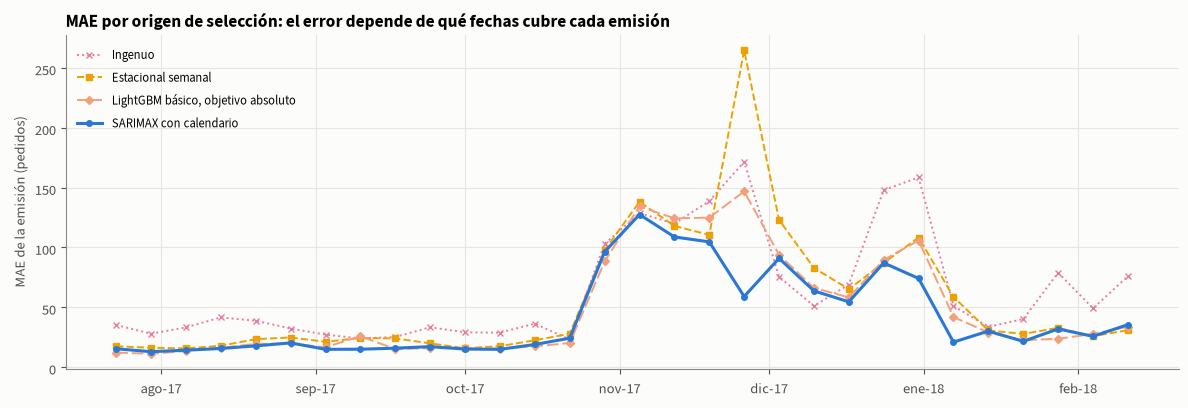


■ Los 10 mayores errores de SARIMAX_calendario en selección
  eventos vacío = día sin evento conocido.


,origen,fecha,h,real,pred,error,eventos
0,2017-10-29,2017-11-24,26,1176,133.9,1042.1,black_friday
1,2017-11-05,2017-11-24,19,1176,139.4,1036.6,black_friday
2,2017-11-12,2017-11-24,12,1176,174.9,1001.1,black_friday
3,2017-11-19,2017-11-24,5,1176,182.7,993.3,black_friday
4,2017-10-29,2017-11-25,27,499,107.9,391.1,post_black_friday
5,2017-11-05,2017-11-25,20,499,112.2,386.8,post_black_friday
6,2017-11-12,2017-11-25,13,499,141.3,357.7,post_black_friday
7,2017-11-19,2017-11-25,6,499,147.5,351.5,post_black_friday
8,2017-10-29,2017-11-26,28,391,120.9,270.1,post_black_friday
9,2017-11-05,2017-11-26,21,391,126.2,264.8,post_black_friday


In [9]:
# Diferencia negativa: el candidato tiene menor MAE que su referencia.
pivote=por_origen.pivot(index='origen',columns='modelo',values='MAE')
comparaciones=[]
for referencia,candidato,idea in [
 ('LGBM_base_absoluto','LGBM_amplio_absoluto','Variables con objetivo absoluto'),
 ('LGBM_base_relativo','LGBM_amplio_relativo','Variables con objetivo relativo'),
 ('LGBM_base_absoluto','LGBM_base_relativo','Objetivo con variables básicas'),
 ('LGBM_amplio_absoluto','LGBM_amplio_relativo','Objetivo con variables ampliadas'),
 ('SARIMAX_solo_semana','SARIMAX_calendario','Eventos de calendario en SARIMAX')]:
    d=pivote[candidato]-pivote[referencia]
    comparaciones.append(dict(comparacion=idea,referencia=referencia,candidato=candidato,
        diferencia_MAE=d.mean(),origenes_mejora=int((d<0).sum()),origenes=len(d)))
ablacion=pd.DataFrame(comparaciones); exportar(ablacion,'comparacion_componentes')
mostrar(ablacion.round(3),'Efecto de cambiar un solo factor (selección)','diferencia_MAE < 0 favorece al candidato.')

fig,ax=plt.subplots(figsize=(12,4.2))
for nombre in dict.fromkeys(['Ingenuo','Estacional_7',mejor_ml,ganador]):
    ax.plot(pivote.index,pivote[nombre],**trazo(nombre,lw=2.2 if nombre==ganador else 1.4,ms=4,label=NOMBRE[nombre]))
ax.set_ylabel('MAE de la emisión (pedidos)'); fechas_es(ax,'mes',1); ax.legend(loc='upper left',fontsize=9)
ax.set_title('MAE por origen de selección: el error depende de qué fechas cubre cada emisión')
figura('mae_origen_seleccion')

# Errores grandes merecen una explicación concreta: se unen a sus eventos en SQL.
con.register('predicciones',p_sel)
peores=consultar(con,'errores_mayores.sql',[ganador,10]); exportar(peores,'errores_mayores_seleccion')
mostrar(peores.round({'pred':1,'error':1}),f'Los 10 mayores errores de {ganador} en selección','eventos vacío = día sin evento conocido.')

**Lectura**

- **Modelar los eventos aporta.** SARIMAX_calendario reduce el MAE en 9,2 pedidos frente a la misma estructura sin eventos y gana en 20 de los 30 orígenes. Es la evidencia más directa de que la decisión de 01 §3.3 vale la pena.
- **En LightGBM, más no es mejor.**
  - Ampliar las variables empeora ligeramente el MAE (+1,8 con objetivo absoluto, +0,7 con relativo): con 30 emisiones y pocas temporadas, las variables extra agregan ruido.
  - El objetivo relativo empeora claramente (+9,4 y +8,3). Ancla el nivel a la media de 28 días del origen, y esa media deja de representar el nivel futuro justo cuando el nivel cambia rápido (noviembre a enero).
- **MAE por origen.** Hasta octubre los modelos útiles están cerca (15–25 pedidos). Las emisiones que cubren Black Friday y fin de año concentran los errores.
  - Estacional_7 llega a 265 en la emisión del 26 de noviembre, porque copia la semana de Black Friday en las cuatro semanas siguientes.
  - SARIMAX se queda en 59: su indicador absorbe el pico en lugar de trasladarlo al nivel.
- **Los diez mayores errores** son Black Friday y sus días posteriores, pronosticados desde los cuatro orígenes previos. Ninguno tenía un Black Friday anterior en su historia, así que el coeficiente no podía estimarse (01 §1). Estas fechas no se eliminan para mejorar la métrica.

**Qué implica.** Se confirma la decisión de modelar los eventos. En LightGBM la variante más simple (LGBM_base_absoluto) es la mejor; es la que se usa como representante de ML en adelante.

## 7. Cómo crece el error con el horizonte (selección)

El taller pide mostrar el error por horizonte frente a los baselines. Se usa primero la selección: cada horizonte tiene 30 emisiones, el doble de información que en prueba, y la curva es más estable. Se grafican ambos baselines, ETS, el SARIMAX principal y el mejor LightGBM.

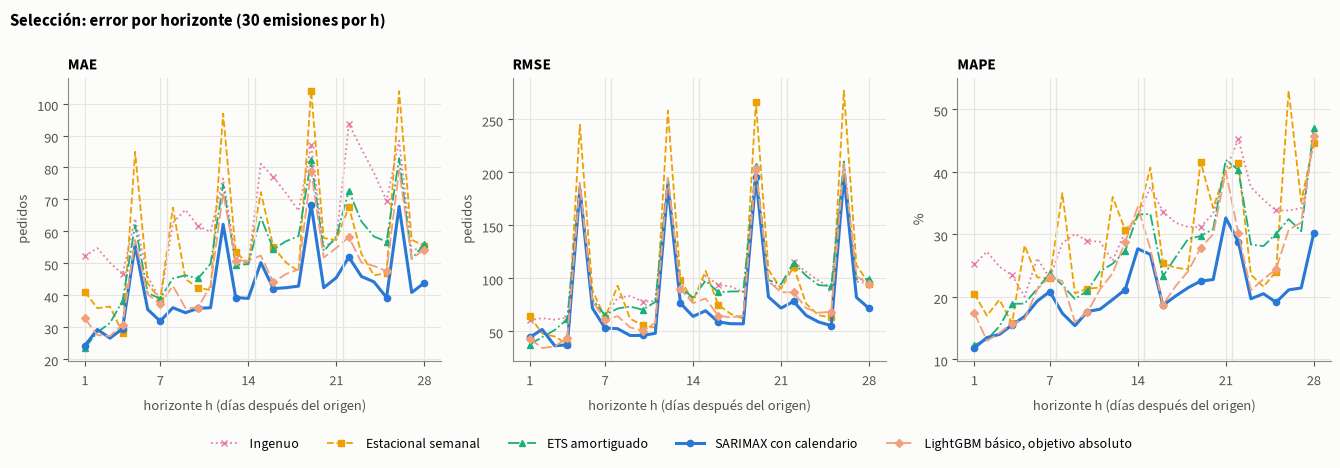


■ Selección: MAE por semana del horizonte y mejora frente a Estacional_7
  Semana 1 = h 1–7 (lunes a domingo siguientes al origen).


MAE                   mejora_vs_Estacional_7_%                  
semana                 1     2     3     4                        1     2     3     4
modelo                                                                               
Ingenuo             50.3  61.2  70.8  75.0                    -14.1  -8.1 -11.7 -22.0
Estacional_7        44.1  56.6  63.4  61.5                      0.0   0.0   0.0   0.0
ETS_amortiguado     37.5  51.5  61.2  63.0                     14.9   9.1   3.6  -2.5
SARIMAX_calendario  33.2  40.4  47.6  47.6                     24.7  28.7  24.9  22.5
LGBM_base_absoluto  36.1  47.3  53.8  55.7                     18.1  16.4  15.3   9.4

In [10]:
# Métricas por horizonte y por semana del horizonte (h 1-7, 8-14, 15-21, 22-28).
representantes=list(dict.fromkeys(['Ingenuo','Estacional_7','ETS_amortiguado','SARIMAX_calendario',mejor_ml,ganador]))
def curvas_horizonte(p,titulo,nombre):
    por_h=metricas(p,('modelo','h'))
    fig,ejes=plt.subplots(1,3,figsize=(13.5,4.3))
    for eje,metrica,unidad in zip(ejes,['MAE','RMSE','MAPE'],['pedidos','pedidos','%']):
        for modelo in representantes:
            g=por_h[por_h.modelo.eq(modelo)]
            eje.plot(g.h,g[metrica],**trazo(modelo,lw=2.2 if modelo==ganador else 1.3,ms=4.5,markevery=(0,3),label=NOMBRE[modelo]))
        eje.set_title(metrica,fontsize=11); eje.set_xlabel('horizonte h (días después del origen)'); eje.set_ylabel(unidad)
        eje.set_xticks([1,7,14,21,28])
        for corte in (7.5,14.5,21.5): eje.axvline(corte,color='#e6e5e0',lw=1)
    fig.suptitle(titulo,x=.01,ha='left',fontweight='bold',fontsize=12)
    plt.tight_layout()
    fig.legend(*ejes[0].get_legend_handles_labels(),loc='lower center',ncol=len(representantes),bbox_to_anchor=(.5,-.08),fontsize=10)
    figura(nombre)
    return por_h
def tabla_semanas(p):
    s=metricas(p.assign(semana=(p.h-1)//7+1),('modelo','semana'))
    mae=s.pivot(index='modelo',columns='semana',values='MAE').loc[representantes]
    mejora=100*(1-mae/mae.loc['Estacional_7'])
    return s,pd.concat({'MAE':mae,'mejora_vs_Estacional_7_%':mejora},axis=1).round(1)
por_h_sel=curvas_horizonte(p_sel,'Selección: error por horizonte (30 emisiones por h)','metricas_horizonte_seleccion')
exportar(por_h_sel,'metricas_horizonte_seleccion')
semanas_sel,vista_sel=tabla_semanas(p_sel); exportar(semanas_sel,'metricas_semana_seleccion')
mostrar(vista_sel,'Selección: MAE por semana del horizonte y mejora frente a Estacional_7','Semana 1 = h 1–7 (lunes a domingo siguientes al origen).')

**Lectura del gráfico y de la tabla**

- **El error crece con el horizonte.**
  - El MAE de SARIMAX pasa de unos 24 pedidos en h = 1 a unos 48 en promedio en h = 22–28.
  - Su MAPE sube de unos 12 % en h = 1 a unos 23 % en promedio en h = 22–28, con picos cercanos al 30 %.
  - Por semana del horizonte: 33 → 40 → 48 → 48 pedidos.
- **Los picos en h = 5, 12, 19 y 26 son una sola fecha:** Black Friday (un viernes), visto desde los cuatro orígenes anteriores. Dominan el RMSE; el MAPE los atenúa porque el real de ese día es muy grande.
- **SARIMAX queda por debajo de ambos baselines en las cuatro semanas**, entre 23 % y 29 % mejor que Estacional_7. El Ingenuo es el peor en todas, porque repite el valor de un domingo para los 28 días.
- **ETS y LightGBM pierden ventaja con el horizonte.**
  - ETS empieza cerca de SARIMAX en la semana 1 y se degrada hasta igualar al estacional en la semana 4. No usa calendario y su tendencia, aunque amortiguada, se aleja con h.
  - La ventaja de LightGBM baja del 18 % al 9 %.

**Qué implica.** La ventaja del modelo elegido se mantiene en los cuatro horizontes semanales, así que un solo modelo sirve para todo el plan. La incertidumbre sí crece con h; por eso los intervalos se calibran por semana del horizonte (§9).

## 8. Convergencia y residuos de SARIMAX

SARIMAX registra la convergencia del optimizador en cada origen. Si el primer algoritmo no converge, se aplica una segunda estrategia fijada previamente; si tampoco converge, la ejecución se detiene.

La prueba Ljung–Box examina autocorrelación residual conjunta. Un p pequeño sugiere estructura que el modelo no absorbió; un p grande no demuestra que el modelo sea correcto. Se muestran las innovaciones estandarizadas del primer origen (tras descartar la inicialización), para que el diagnóstico no use datos de evaluación.


■ SARIMAX_calendario en las 30 emisiones de selección
  Ljung–Box: p < 0,05 sugiere autocorrelación residual.


,origen,convergencia,optimizador,Ljung_Box_p7,Ljung_Box_p14
4,2017-07-23,True,lbfgs,0.0273,0.1297
13,2017-07-30,True,lbfgs,0.0188,0.0993
22,2017-08-06,True,lbfgs,0.0156,0.0898
31,2017-08-13,True,lbfgs,0.0141,0.0768
40,2017-08-20,True,lbfgs,0.0161,0.0779
49,2017-08-27,True,lbfgs,0.0176,0.0749
58,2017-09-03,True,lbfgs,0.0150,0.0618
67,2017-09-10,True,lbfgs,0.0126,0.0478
76,2017-09-17,True,lbfgs,0.0155,0.0454
85,2017-09-24,True,lbfgs,0.0141,0.0385


Convergen 30 de 30. Ljung–Box p7 < 0,05 en 21 emisiones.


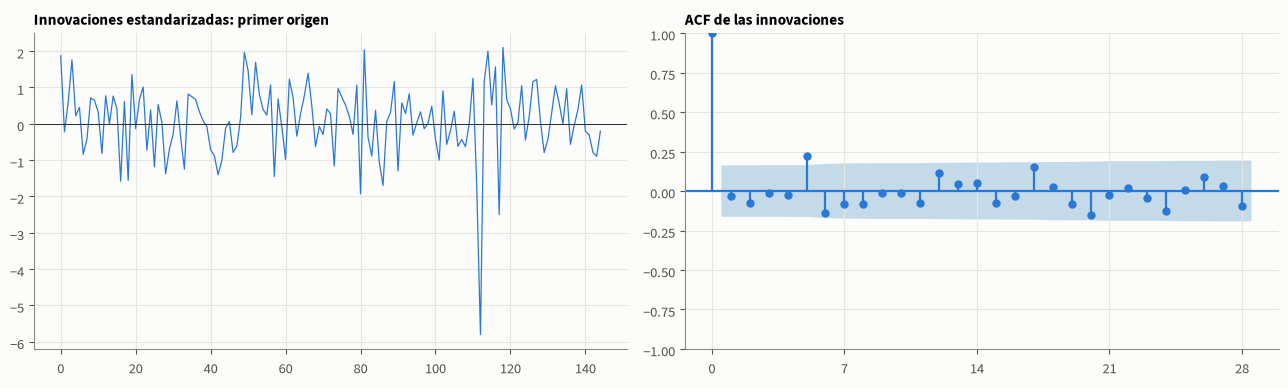


■ Coeficientes del primer ajuste (escala log)
  Un coeficiente de día ≈ diferencia en log frente al domingo; exp(coef) − 1 ≈ efecto porcentual.


,coeficiente
festivo,-0.118
carnaval,-0.475
dia_1,0.301
dia_2,0.275
dia_3,0.221
dia_4,0.188
dia_5,0.091
dia_6,-0.099
ar.L1,0.067
ma.L1,-0.699


In [11]:
# Ajuste del primer origen para visualizar residuos y sus límites.
from statsmodels.graphics.tsaplots import plot_acf
_,detalle_sar=predecir('SARIMAX_calendario',y,variables,calendario,SELECCION[0],detalles=True)
residuos=np.asarray(detalle_sar.pop('residuos'))
coeficientes=detalle_sar.pop('coeficientes')
for clave in ['inferior_param','superior_param']: detalle_sar.pop(clave)
(ROOT/'resultados/diagnostico_sarimax.json').write_text(json.dumps(detalle_sar,ensure_ascii=False,indent=2),encoding='utf-8')
sar=aj_sel[aj_sel.modelo.eq('SARIMAX_calendario')]
mostrar(sar[['origen','convergencia','optimizador','Ljung_Box_p7','Ljung_Box_p14']].round(4),
        'SARIMAX_calendario en las 30 emisiones de selección','Ljung–Box: p < 0,05 sugiere autocorrelación residual.')
print(f'Convergen {int(sar.convergencia.sum())} de {len(sar)}. Ljung–Box p7 < 0,05 en {int(sar.Ljung_Box_p7.lt(.05).sum())} emisiones.')
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(residuos,color=COLOR['SARIMAX_calendario'],lw=.9); ax[0].axhline(0,color=TINTA,lw=.7)
ax[0].set_title('Innovaciones estandarizadas: primer origen',fontsize=11)
plot_acf(residuos,lags=28,ax=ax[1],color=COLOR['SARIMAX_calendario'],vlines_kwargs={'colors':COLOR['SARIMAX_calendario']})
ax[1].set_title('ACF de las innovaciones',fontsize=11); ax[1].set_xticks(range(0,29,7))
figura('residuos_sarimax')
mostrar(pd.Series(coeficientes).round(3).to_frame('coeficiente'),'Coeficientes del primer ajuste (escala log)',
        'Un coeficiente de día ≈ diferencia en log frente al domingo; exp(coef) − 1 ≈ efecto porcentual.')

**Lectura**

- **Convergencia:** los 30 ajustes convergen con el primer optimizador.
- **Ljung–Box a 7 rezagos** rechaza la ausencia de autocorrelación (p < 0,05) en 21 de las 30 emisiones. Queda algo de estructura semanal sin absorber.
  - La ACF del primer origen muestra un pico en el rezago 5 (≈ 0,22).
  - Es coherente con 01 §2.2: el domingo es el día cuyo perfil más cambió entre ventanas, y seis indicadores fijos no capturan ese desplazamiento.
- **La innovación de −5,8** (alrededor del índice 112) es el 21 de junio de 2017, la caída sin explicación que 01 §3.1 marcó y conservó.
- **Coeficientes del primer ajuste:**
  - lunes ≈ +35 % frente al domingo (`exp(0,301) − 1`) y sábado ≈ −9 %;
  - festivo ≈ −11 % y carnaval ≈ −38 %, este último estimado con un solo Carnaval (2017);
  - MA(1) = −0,70, el componente que 01 §2.6 anticipó; el AR(1) es pequeño (0,07).

**Qué implica.** El modelo es útil pero no perfecto. Su intervalo paramétrico supone innovaciones independientes y normales, así que probablemente sea optimista; §14 lo contrasta con intervalos calibrados con errores reales.

## 9. Calibrar la incertidumbre en una etapa reservada

El modelo ya está elegido. Ahora se reajusta en 12 orígenes posteriores que **no** participaron en la selección; sus errores sirven para estimar márgenes. Usar los errores de selección reutilizaría los mismos errores con los que se eligió el modelo y daría márgenes demasiado optimistas.

**Intervalo conformal por semana del horizonte.** Para cada semana del horizonte se ordenan los errores de calibración y se toma el de rango `⌈(n+1)×0,90⌉`. Con 12 emisiones × 7 días hay 84 errores por semana y se toma el número 77. Se comparan dos escalas definidas de antemano:

- **relativo** (principal): error `|real − pred| / (1 + pred)`; el intervalo es `pred ± q × (1 + pred)`. El margen crece con el nivel, coherente con la amplitud proporcional de 01 §2.3.
- **absoluto**: error `|real − pred|`; el intervalo es `pred ± q`.

Además se calibra el mismo intervalo relativo para el **mejor LightGBM**, con sus propias predicciones en los 12 orígenes, para comparar con el intervalo paramétrico del modelo estadístico en §14.

La dependencia temporal, el solapamiento y el reajuste impiden prometer cobertura conformal exacta: el 90 % es un objetivo nominal que se contrasta con cobertura y amplitud observadas.

**Huelga.** Cae en esta etapa. Según 01 §3.3 se **conserva**: el principal incluye sus errores. Como sensibilidad descriptiva se muestra cuánto cambiarían los cuantiles sin esos días.

In [12]:
# El candidato ya está fijado; estos errores solo calibran incertidumbre.
modelos_cal=list(dict.fromkeys([ganador,mejor_ml,'SARIMAX_calendario']))
p_cal_todos,aj_cal_todos=evaluar(y,variables,calendario,CALIBRACION,modelos_cal)
p_cal=p_cal_todos[p_cal_todos.modelo.eq(ganador)].reset_index(drop=True)
p_cal_ml=p_cal_todos[p_cal_todos.modelo.eq(mejor_ml)].reset_index(drop=True)
exportar(p_cal,'predicciones_calibracion'); exportar(aj_cal_todos[aj_cal_todos.modelo.eq(ganador)],'ajustes_calibracion')
exportar(p_cal_ml,'predicciones_calibracion_ml')
cal_diaria={m:calibrar(p_cal,metodo=m) for m in ['absoluto','relativo']}
cal_semanal={m:calibrar(p_cal,metodo=m,semanal=True) for m in ['absoluto','relativo']}
cuantiles=pd.concat([*cal_diaria.values(),*cal_semanal.values()],ignore_index=True); exportar(cuantiles,'cuantiles_intervalos')
cal_ml=calibrar(p_cal_ml,metodo='relativo'); exportar(cal_ml,'cuantiles_intervalos_ml')
# Sensibilidad: mismos cuantiles relativos sin los días de huelga (no se usan como principal).
huelga=etiquetas.loc[etiquetas.evento.eq('huelga_camioneros'),'fecha']
sin_huelga=calibrar(p_cal[~p_cal.fecha.isin(huelga)],metodo='relativo')
vista_q=pd.DataFrame({f'{ganador} relativo (principal)':cal_diaria['relativo'].set_index('semana').cuantil,
                      f'{ganador} relativo sin huelga':sin_huelga.set_index('semana').cuantil,
                      f'{ganador} absoluto (pedidos)':cal_diaria['absoluto'].set_index('semana').cuantil,
                      f'{mejor_ml} relativo':cal_ml.set_index('semana').cuantil})
mostrar(vista_q.round(3),'Cuantiles del 90 % por semana del horizonte (calibración)',
        'Relativo: 0,30 significa ±30 % de (1 + pronóstico). Absoluto: ± pedidos.')
mostrar(cuantiles,'Detalle de los 16 cuantiles del modelo seleccionado','n errores, rango usado y valor; diarios y de totales semanales.')

2018-03-11: 2 modelos, 28 horizontes.


2018-03-18: 2 modelos, 28 horizontes.


2018-03-25: 2 modelos, 28 horizontes.


2018-04-01: 2 modelos, 28 horizontes.


2018-04-08: 2 modelos, 28 horizontes.


...

2018-05-27: 2 modelos, 28 horizontes.



■ Cuantiles del 90 % por semana del horizonte (calibración)
  Relativo: 0,30 significa ±30 % de (1 + pronóstico). Absoluto: ± pedidos.


,SARIMAX_calendario relativo (principal),SARIMAX_calendario relativo sin huelga,SARIMAX_calendario absoluto (pedidos),LGBM_base_absoluto relativo
semana,,,,
1,0.423,0.275,69.132,0.305
2,0.550,0.427,105.854,0.538
3,0.549,0.447,139.060,0.566
4,0.514,0.491,110.002,0.528



■ Detalle de los 16 cuantiles del modelo seleccionado
  n errores, rango usado y valor; diarios y de totales semanales.


,semana,n,rango,cuantil,metodo,unidad,nivel
0,1,84,77,69.131963,absoluto,diaria,0.9
1,2,84,77,105.854045,absoluto,diaria,0.9
2,3,84,77,139.059703,absoluto,diaria,0.9
3,4,84,77,110.001538,absoluto,diaria,0.9
4,1,84,77,0.422553,relativo,diaria,0.9
5,2,84,77,0.549552,relativo,diaria,0.9
6,3,84,77,0.548860,relativo,diaria,0.9
7,4,84,77,0.513981,relativo,diaria,0.9
8,1,12,12,603.415835,absoluto,total_semanal,0.9
9,2,12,12,892.074355,absoluto,total_semanal,0.9


**Lectura**

- **Los márgenes crecen de la semana 1 a la 2 y luego se estabilizan.** En la semana 1 el intervalo relativo es ±42 % de (1 + pronóstico); en las semanas 2 a 4, entre ±51 % y ±55 %.
- **La huelga pesa mucho.** Sin esos días, el cuantil de la semana 1 bajaría de 0,42 a 0,27, y el de la semana 2 de 0,55 a 0,43. El principal la conserva (01 §3.3), porque un plan real debe contemplar choques así.
- **LGBM_base_absoluto** tiene un margen más estrecho en la semana 1 (0,31) y parecido en las demás.
- **Los totales semanales**, con solo 12 residuos, usan el máximo: ±39 % la primera semana y entre ±63 % y ±71 % las siguientes. Son muy amplios y están dominados por la huelga.

**Qué implica.** Los intervalos quedan fijos antes de la prueba, con márgenes anchos que reflejan un período de calibración con un choque fuerte. §14 mide su cobertura.

## 10. Intervalos de totales semanales

Una semana operativa comprende h1–h7 (lunes a domingo), la siguiente h8–h14, etc. Primero se suman los siete reales y las siete predicciones; luego se calcula el error de ese **total**. Su cuantil produce un intervalo específico para la semana.

Hay solo 12 residuos de total por posición semanal; para el 90 % el rango es 12, es decir, se usa el máximo. Es un cálculo finito y verificable, pero sensible a pocos episodios.

**No se suman límites diarios.** Aunque cada intervalo diario cubra el 90 %, la probabilidad de que los siete cubran a la vez puede ser muy distinta.

In [13]:
# Agrupamos puntos y reales antes de construir márgenes para totales.
totales_cal=totales_semanales(p_cal); exportar(totales_cal,'totales_semanales_calibracion')
assert len(totales_cal)==len(CALIBRACION)*4
mostrar(totales_cal.head(8).round({'real':1,'pred':1}),'Totales semanales de calibración (primeras dos emisiones)',
        'Cada fila es un total de siete días de una emisión, no un límite diario sumado.')


■ Totales semanales de calibración (primeras dos emisiones)
  Cada fila es un total de siete días de una emisión, no un límite diario sumado.


,modelo,origen,semana,desde,hasta,real,pred
0,SARIMAX_calendario,2018-03-11,1,2018-03-12,2018-03-18,1595.0,1715.5
1,SARIMAX_calendario,2018-03-11,2,2018-03-19,2018-03-25,1716.0,1711.6
2,SARIMAX_calendario,2018-03-11,3,2018-03-26,2018-04-01,1471.0,1668.8
3,SARIMAX_calendario,2018-03-11,4,2018-04-02,2018-04-08,1590.0,1711.6
4,SARIMAX_calendario,2018-03-18,1,2018-03-19,2018-03-25,1716.0,1689.4
5,SARIMAX_calendario,2018-03-18,2,2018-03-26,2018-04-01,1471.0,1643.1
6,SARIMAX_calendario,2018-03-18,3,2018-04-02,2018-04-08,1590.0,1685.6
7,SARIMAX_calendario,2018-03-18,4,2018-04-09,2018-04-15,1554.0,1685.6


## 11. Prueba retrospectiva: las últimas ocho semanas útiles

Se evalúan cinco emisiones. Son 140 pares por modelo y 56 fechas distintas; las fechas centrales se pronostican hasta cuatro veces con anticipaciones diferentes. Cada origen puede usar las ventas de prueba anteriores a esa emisión: es el reajuste operativo legítimo. El candidato seleccionado y los cuantiles de los intervalos permanecen fijos; **no se elige otro ganador por mirar esta tabla**.

Además de la métrica por par, se calcula una versión donde **cada fecha pesa igual** (primero se promedian sus emisiones), para que el solapamiento no dé más peso a las fechas centrales.

In [14]:
p_test,aj_test=evaluar(y,variables,calendario,PRUEBA,MODELOS)
exportar(p_test,'predicciones_prueba'); exportar(aj_test,'ajustes_prueba')
print(f'Fechas objetivo de prueba: {fecha_es(p_test.fecha.min())} a {fecha_es(p_test.fecha.max())}.')
m_test=metricas(p_test).sort_values(['MAE','modelo']); exportar(m_test,'metricas_prueba')
por_origen_test=metricas(p_test,('modelo','origen'))
for etapa,p in [('prueba',p_test)]:
    exportar(metricas(p,('modelo','h')),f'metricas_horizonte_{etapa}')
    exportar(metricas(p.assign(semana=(p.h-1)//7+1),('modelo','semana')),f'metricas_semana_{etapa}')
    exportar(por_origen_test,f'metricas_origen_{etapa}')
mostrar(tabla_comparativa(m_test,por_origen_test).round(2),'Prueba: 5 emisiones × 28 horizontes = 140 pares por modelo',
        'Descriptivo: el ganador ya estaba fijado.')
# Igual peso por fecha: primero promediamos pérdidas de sus emisiones, luego fechas.
con.register('predicciones',p_test)
igual_fecha=consultar(con,'metricas_igual_peso_fecha.sql'); exportar(igual_fecha,'metricas_prueba_igual_peso_fecha')
peso=consultar(con,'peso_fechas.sql',['Estacional_7']); exportar(peso,'peso_fechas_prueba')
mostrar(igual_fecha.round(2),'Prueba con igual peso por fecha (56 fechas)',
        f'Cada fecha recibe entre {peso.emisiones.min()} y {peso.emisiones.max()} emisiones.')
print(f'Ganador fijado en selección: {ganador}. Mejor MAE observado en prueba: {m_test.iloc[0].modelo}.')

2018-06-24: 9 modelos, 28 horizontes.


2018-07-01: 9 modelos, 28 horizontes.


2018-07-08: 9 modelos, 28 horizontes.


2018-07-15: 9 modelos, 28 horizontes.


2018-07-22: 9 modelos, 28 horizontes.


Fechas objetivo de prueba: 25 de jun de 2018 a 19 de ago de 2018.

■ Prueba: 5 emisiones × 28 horizontes = 140 pares por modelo
  Descriptivo: el ganador ya estaba fijado.


,MAE,RMSE,MAPE,sMAPE,sesgo,n,desv_MAE_origenes,mejora_vs_Estacional_7_%
modelo,,,,,,,,
ETS_amortiguado,60.84,75.50,27.11,29.44,-36.98,140,28.85,8.40
SARIMAX_calendario,61.50,75.96,27.42,29.68,-37.23,140,30.05,7.41
SARIMAX_solo_semana,61.99,76.37,27.56,29.80,-37.94,140,29.59,6.67
Estacional_7,66.42,84.58,29.83,32.56,-37.04,140,34.11,0.00
LGBM_base_absoluto,66.75,81.52,29.79,32.20,-41.19,140,31.30,-0.50
LGBM_base_relativo,69.39,86.47,30.65,33.49,-41.69,140,34.15,-4.47
LGBM_amplio_absoluto,70.24,86.22,30.99,34.01,-44.62,140,32.45,-5.74
LGBM_amplio_relativo,71.51,88.46,31.40,34.90,-45.25,140,36.55,-7.66
Ingenuo,77.61,94.06,32.33,37.69,-59.61,140,29.18,-16.84



■ Prueba con igual peso por fecha (56 fechas)
  Cada fecha recibe entre 1 y 4 emisiones.


,modelo,MAE,RMSE,MAPE,sMAPE,fechas
0,ETS_amortiguado,53.93,69.98,24.46,25.93,56
1,SARIMAX_calendario,55.05,70.98,24.89,26.39,56
2,SARIMAX_solo_semana,56.03,71.73,25.24,26.74,56
3,Estacional_7,60.47,80.55,27.10,29.20,56
4,LGBM_base_absoluto,61.80,77.88,27.63,29.46,56
5,LGBM_base_relativo,64.37,82.98,28.54,30.80,56
6,LGBM_amplio_absoluto,65.14,82.64,28.76,31.16,56
7,LGBM_amplio_relativo,66.36,84.64,29.22,32.07,56
8,Ingenuo,72.98,89.68,30.88,34.92,56


Ganador fijado en selección: SARIMAX_calendario. Mejor MAE observado en prueba: ETS_amortiguado.


**Lectura de la tabla**

- **El ganador mejora a los baselines.** SARIMAX_calendario obtiene un MAE de 61,5, un 7,4 % mejor que Estacional_7 (66,4) y un 21 % mejor que el Ingenuo.
- **ETS_amortiguado obtiene el menor MAE de prueba (60,8).** La diferencia con SARIMAX es de 0,7 pedidos, mucho menor que la variación entre emisiones (desviación ≈ 30). No se cambia de ganador por mirar esta tabla.
- **Los tres modelos estadísticos superan a ambos baselines en las cuatro métricas.** Ningún LightGBM mejora a Estacional_7 en prueba (§18 explica por qué).
- **Todos empeoran respecto a la selección y subpronostican** (sesgo ≈ −37 pedidos en los estadísticos). §16 muestra que el sesgo se concentra en agosto.
- **Con igual peso por fecha el orden no cambia.**

**Qué implica.** La ventaja del enfoque estadístico se mantiene, pero se reduce del 25 % al 7 %. ETS y SARIMAX, que comparten el diagnóstico de 01 (escala log, semana multiplicativa, tendencia que no se extrapola), quedan prácticamente empatados.

## 12. Error por horizonte en prueba

Misma lectura que §7, ahora con solo cinco emisiones por horizonte. Una curva irregular es esperable: cada horizonte evalúa fechas distintas y pocas.

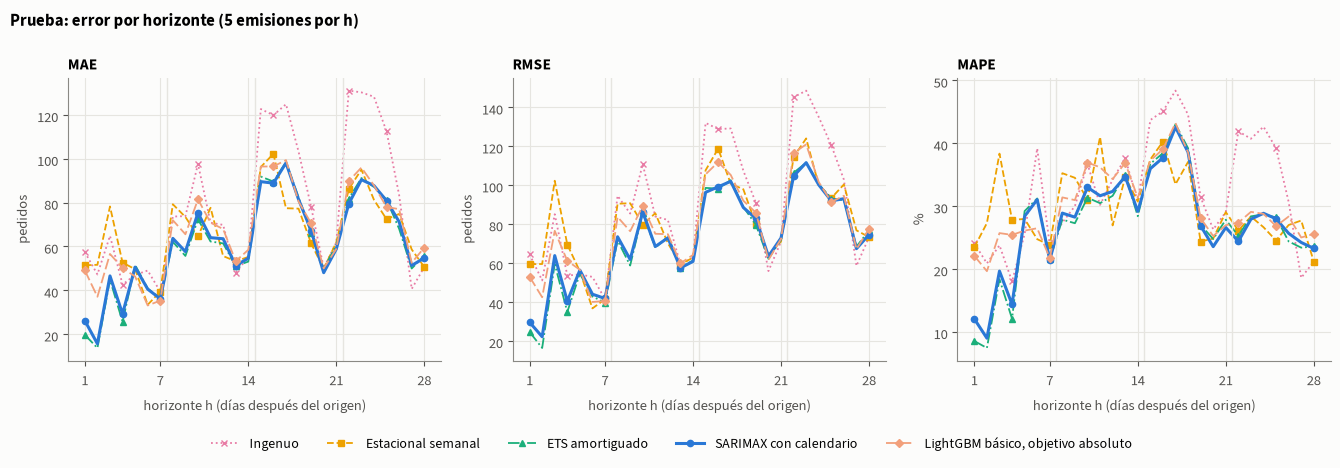


■ Prueba: MAE por semana del horizonte y mejora frente a Estacional_7
  Pocas emisiones: leer como descripción, no como ley general.


MAE                   mejora_vs_Estacional_7_%                 
semana                 1     2     3     4                        1    2     3     4
modelo                                                                              
Ingenuo             49.6  69.8  94.3  96.6                      2.5 -6.5 -25.6 -30.4
Estacional_7        50.9  65.5  75.1  74.1                      0.0  0.0   0.0   0.0
ETS_amortiguado     33.2  59.7  76.9  73.6                     34.8  8.9  -2.4   0.7
SARIMAX_calendario  35.0  61.4  76.0  73.7                     31.3  6.3  -1.1   0.6
LGBM_base_absoluto  43.9  67.0  78.9  77.2                     13.7 -2.3  -4.9  -4.2

In [15]:
# Mismas curvas y tabla semanal que en selección, para comparar contra los baselines.
por_h_test=curvas_horizonte(p_test,'Prueba: error por horizonte (5 emisiones por h)','metricas_horizonte_prueba')
_,vista_test=tabla_semanas(p_test)
mostrar(vista_test,'Prueba: MAE por semana del horizonte y mejora frente a Estacional_7','Pocas emisiones: leer como descripción, no como ley general.')

**Lectura del gráfico y de la tabla**

- **Semana 1:** los modelos estadísticos tienen un MAE de unos 33–35 pedidos, un tercio menos que Estacional_7 (51).
- **Semanas 2 a 4:** la ventaja casi desaparece. En las semanas 3 y 4 todos los modelos útiles rondan 74–79 pedidos.
- **Entre h ≈ 8 y h ≈ 24 el error sube mucho**, porque esas fechas caen sobre todo en el valle de inicios de julio y en el salto de agosto, que nadie anticipó (§13 y §16). Los últimos horizontes cubren pocas fechas distintas y bajan por eso, no porque el modelo mejore.
- **El Ingenuo** es claramente el peor desde la semana 3.

**Qué implica.** En prueba, el valor del modelo está sobre todo en la primera semana; a tres o cuatro semanas, su error es comparable con repetir la última semana. Esto respalda reajustar cada domingo, como hace el protocolo, y leer las semanas lejanas con sus intervalos.

## 13. Pronósticos frente a lo observado

Dos emisiones de prueba —la primera y la última— muestran cómo se comportan los pronósticos a lo largo de los 28 días frente a lo que ocurrió. La línea gris a la izquierda es la historia que veía el modelo al emitir.

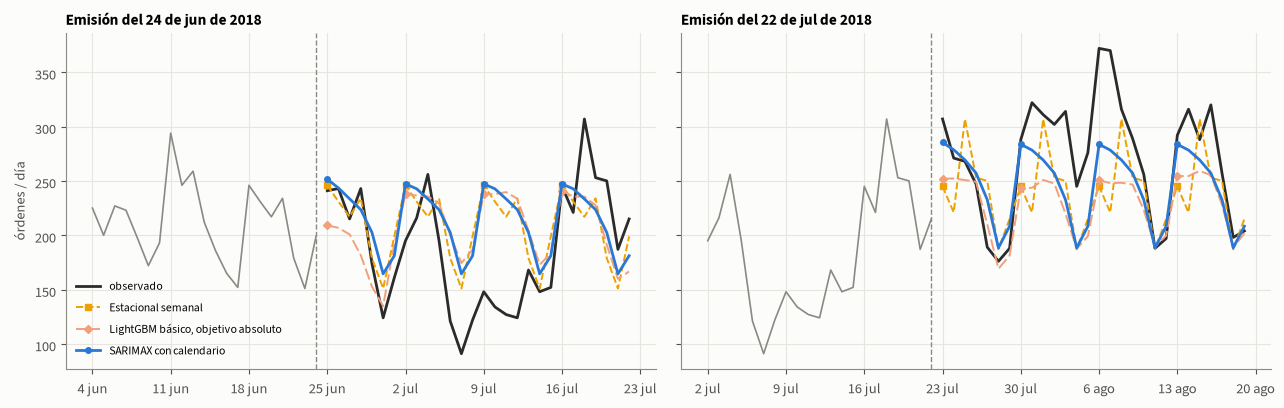

In [16]:
# Comparamos baselines, el ganador y el mejor ML en la primera y la última emisión de prueba.
fig,ejes=plt.subplots(1,2,figsize=(13,4.2),sharey=True)
for eje,origen in zip(ejes,[PRUEBA[0],PRUEBA[-1]]):
    historia=y[origen-pd.Timedelta(days=20):origen]
    eje.plot(historia.index,historia.values,color=TENUE,lw=1.2)
    g=p_test[p_test.origen.eq(origen)]
    real=g[g.modelo.eq(ganador)]
    eje.plot(real.fecha,real.real,color=TINTA,lw=2,label='observado')
    for nombre in dict.fromkeys(['Estacional_7',mejor_ml,ganador]):
        t=g[g.modelo.eq(nombre)]
        eje.plot(t.fecha,t.pred,**trazo(nombre,lw=2 if nombre==ganador else 1.4,ms=4,markevery=7,label=NOMBRE[nombre]))
    eje.axvline(origen,color=TENUE,ls='--',lw=1)
    eje.set_title(f'Emisión del {fecha_es(origen)}',fontsize=11); fechas_es(eje,'semana',1)
ejes[0].set_ylabel('órdenes / día'); ejes[0].legend(loc='lower left',fontsize=8.5)
figura('pronosticos_prueba')

**Lectura del gráfico**

- **Emisión del 24 de junio.** Los tres modelos siguen bien la primera semana. Entre el 6 y el 14 de julio la demanda cae a 90–150 órdenes diarias, un valle que ninguno anticipa: siguen pronosticando el nivel de junio.
  - El valle coincide con la fase eliminatoria del Mundial (Brasil jugó el 2 y el 6 de julio).
  - Dos partidos no explican por sí solos una semana entera, así que queda como hipótesis.
- **Emisión del 22 de julio.** La forma semanal es correcta, pero a inicios de agosto el nivel real sube a 300–370 órdenes y todos los pronósticos quedan por debajo. LightGBM es el más plano: no supera unas 260 órdenes.

**Qué implica.** Los errores grandes de la prueba son de **nivel**, no de forma semanal. Un modelo que solo conoce el pasado no puede anticipar un cambio de nivel sin una causa observable, como una campaña comercial.

## 14. Intervalos de predicción y cobertura empírica

Se comparan cuatro intervalos del 90 % nominal, todos fijados antes de mirar la prueba:

| Intervalo | Modelo | Cómo se construye | Supuesto principal |
|---|---|---|---|
| **Paramétrico** | SARIMAX_calendario | Varianza de pronóstico del filtro de Kalman en log, transformada con `expm1` | Errores normales y modelo bien especificado |
| **Conformal relativo** (principal) | Seleccionado | Cuantil de `|e| / (1+pred)` en calibración, por semana de h | Los errores futuros se parecen a los de calibración |
| Conformal absoluto | Seleccionado | Cuantil de `|e|` en calibración, por semana de h | Igual, con margen fijo en pedidos |
| Conformal relativo ML | Mejor LightGBM | Igual al principal, con los errores del LightGBM | Igual |

**Cobertura** = proporción de reales dentro de los límites. **Amplitud** = límite superior − inferior, en pedidos. Una cobertura alta con intervalos enormes tiene poca utilidad operativa: ambas se leen juntas. El intervalo principal **no** se reemplaza por el que mejor cubra en prueba.


■ Prueba: cobertura y amplitud media de los intervalos diarios del 90 % nominal
  140 pares por método.


,metodo_intervalo,cubiertos,n,cobertura,ancho_medio
0,Conformal absoluto · SARIMAX con calendario,121,140,0.864,211.654
1,"Conformal relativo · LightGBM básico, objetivo...",99,140,0.707,183.726
2,Paramétrico · SARIMAX con calendario,103,140,0.736,188.187
3,Conformal relativo · SARIMAX con calendario (p...,107,140,0.764,196.540


Paramétrico de SARIMAX en calibración: cobertura 85.4%, amplitud media 192 pedidos.

■ Prueba: cobertura de los intervalos de totales semanales (20 totales)
  Calibrados con totales, no sumando límites diarios.


,metodo_intervalo,cubiertos,n,cobertura,ancho_medio
0,absoluto,17,20,0.85,1517.585
1,relativo,16,20,0.80,1597.964


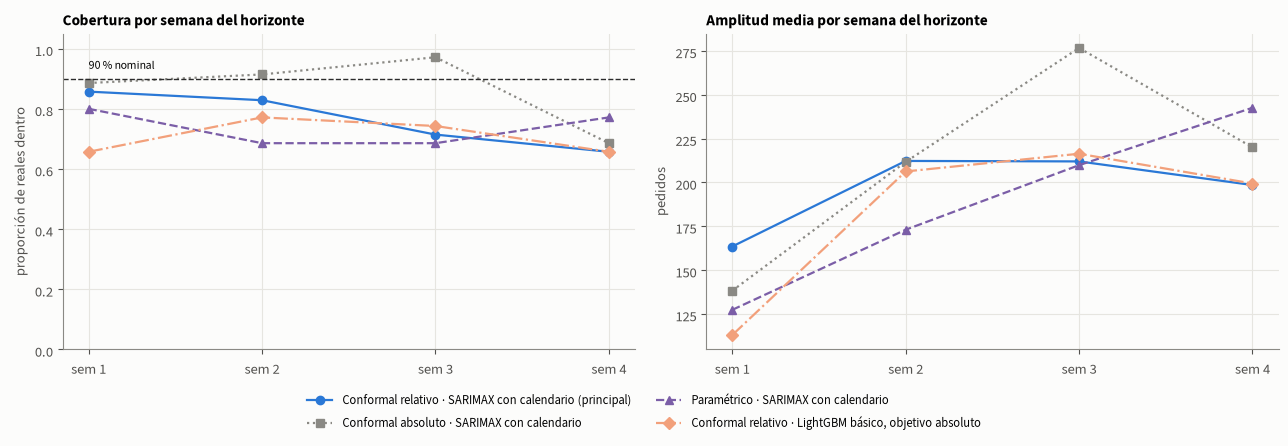

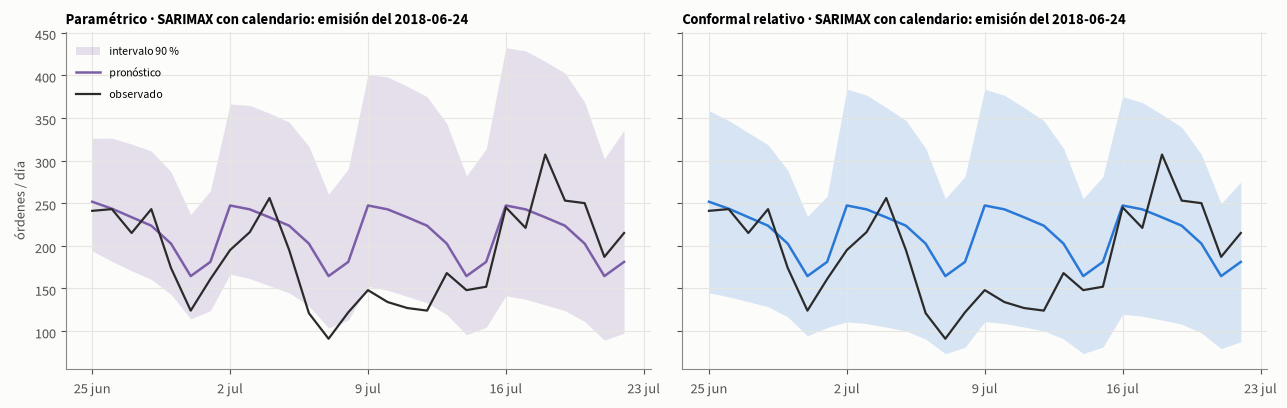

In [17]:
# Aplicamos cuantiles reservados: ninguno se estima con los errores de prueba.
seleccionado_test=p_test[p_test.modelo.eq(ganador)].copy()
i_test=pd.concat([aplicar_intervalos(seleccionado_test,cal_diaria[m]) for m in cal_diaria],ignore_index=True)
i_sem=pd.concat([aplicar_intervalos(seleccionado_test,cal_semanal[m],semanal=True) for m in cal_semanal],ignore_index=True)
exportar(i_test,'intervalos_diarios_prueba'); exportar(i_sem,'intervalos_semanales_prueba')
cov_d=cobertura(i_test); cov_s=cobertura(i_sem)
exportar(cov_d,'cobertura_diaria'); exportar(cov_s,'cobertura_semanal')
exportar(cobertura(i_test,('metodo_intervalo','semana')),'cobertura_diaria_por_semana')
exportar(cobertura(i_sem,('metodo_intervalo','semana')),'cobertura_semanal_por_semana')

def parametrico(p):
    """Intervalo propio de SARIMAX_calendario, en el formato de aplicar_intervalos."""
    s=p[p.modelo.eq('SARIMAX_calendario')].copy()
    return s.assign(semana=(s.h-1)//7+1,inferior=s.inferior_param,superior=s.superior_param,metodo_intervalo='parametrico_sarimax')
param_test=parametrico(p_test)
ml_test=aplicar_intervalos(p_test[p_test.modelo.eq(mejor_ml)],cal_ml).assign(metodo_intervalo='conformal_ml')
todos=pd.concat([i_test,param_test,ml_test],ignore_index=True)
cov_metodos=cobertura(todos); exportar(cov_metodos,'cobertura_metodos')
cov_metodos_sem=cobertura(todos,('metodo_intervalo','semana')); exportar(cov_metodos_sem,'cobertura_metodos_por_semana')
cov_param_cal=cobertura(parametrico(p_cal_todos)); exportar(cov_param_cal,'cobertura_metodos_calibracion')
NOMBRES_INTERVALO={'relativo':f'Conformal relativo · {NOMBRE[ganador]} (principal)','absoluto':f'Conformal absoluto · {NOMBRE[ganador]}',
                   'parametrico_sarimax':'Paramétrico · SARIMAX con calendario','conformal_ml':f'Conformal relativo · {NOMBRE[mejor_ml]}'}
mostrar(cov_metodos.assign(metodo_intervalo=cov_metodos.metodo_intervalo.map(NOMBRES_INTERVALO)).round(3),
        'Prueba: cobertura y amplitud media de los intervalos diarios del 90 % nominal','140 pares por método.')
print(f'Paramétrico de SARIMAX en calibración: cobertura {cov_param_cal.cobertura.iloc[0]:.1%}, '
      f'amplitud media {cov_param_cal.ancho_medio.iloc[0]:.0f} pedidos.')
mostrar(cov_s.round(3),'Prueba: cobertura de los intervalos de totales semanales (20 totales)','Calibrados con totales, no sumando límites diarios.')

fig,ejes=plt.subplots(1,2,figsize=(13,4))
for metodo,nombre in NOMBRES_INTERVALO.items():
    g=cov_metodos_sem[cov_metodos_sem.metodo_intervalo.eq(metodo)]
    color={'relativo':COLOR[ganador],'absoluto':TENUE,'parametrico_sarimax':'#7b5ea7','conformal_ml':COLOR[mejor_ml]}[metodo]
    estilo={'relativo':('-','o'),'absoluto':(':','s'),'parametrico_sarimax':('--','^'),'conformal_ml':('-.','D')}[metodo]
    ejes[0].plot(g.semana,g.cobertura,linestyle=estilo[0],marker=estilo[1],ms=6,color=color,label=nombre)
    ejes[1].plot(g.semana,g.ancho_medio,linestyle=estilo[0],marker=estilo[1],ms=6,color=color,label=nombre)
ejes[0].axhline(NIVEL,color=TINTA,ls='--',lw=1); ejes[0].text(1,NIVEL+.02,'90 % nominal',va='bottom',fontsize=8.5)
ejes[0].set_ylim(0,1.05); ejes[0].set_title('Cobertura por semana del horizonte',fontsize=11); ejes[0].set_ylabel('proporción de reales dentro')
ejes[1].set_title('Amplitud media por semana del horizonte',fontsize=11); ejes[1].set_ylabel('pedidos')
for eje in ejes: eje.set_xticks([1,2,3,4],['sem 1','sem 2','sem 3','sem 4'])
plt.tight_layout()
fig.legend(*ejes[0].get_legend_handles_labels(),loc='lower center',ncol=2,bbox_to_anchor=(.5,-.12),fontsize=9)
figura('cobertura_intervalos')

fig,ejes=plt.subplots(1,2,figsize=(13,4.2),sharey=True)
principal=i_test[i_test.metodo_intervalo.eq('relativo')]
for eje,(nombre,datos,color) in zip(ejes,[('Paramétrico · SARIMAX con calendario',param_test,'#7b5ea7'),
                                          (f'Conformal relativo · {NOMBRE[ganador]}',principal,COLOR[ganador])]):
    g=datos[datos.origen.eq(PRUEBA[0])]
    eje.fill_between(g.fecha,g.inferior,g.superior,color=color,alpha=.18,lw=0,label='intervalo 90 %')
    eje.plot(g.fecha,g.pred,color=color,lw=1.8,label='pronóstico')
    eje.plot(g.fecha,g.real,color=TINTA,lw=1.6,label='observado')
    eje.set_title(f'{nombre}: emisión del {PRUEBA[0].date()}',fontsize=10.5); fechas_es(eje,'semana',1)
ejes[0].set_ylabel('órdenes / día'); ejes[0].legend(loc='upper left',fontsize=8.5)
figura('evaluacion_intervalos')

**Lectura de las tablas y figuras**

- **Ningún intervalo alcanza el 90 % nominal en prueba.**

  | Intervalo | Cobertura en prueba | Amplitud media |
  |---|---|---|
  | Conformal relativo (principal) | 76,4 % (107 de 140) | ≈ 197 pedidos |
  | Paramétrico de SARIMAX | 73,6 % | ≈ 188 pedidos |
  | Conformal de LightGBM | 70,7 % | ≈ 184 pedidos |
  | Conformal absoluto | 86,4 % | ≈ 212 pedidos |
- **El paramétrico ya era optimista antes de la prueba:** en calibración cubrió el 85,4 %, por debajo del 90 %. Es coherente con la autocorrelación residual de §8.
- **Por semana del horizonte:**
  - el principal cubre el 86 % en la semana 1 y cae al 66 % en la semana 4;
  - la amplitud del paramétrico crece con h (de unos 127 a unos 242 pedidos), como corresponde a un pronóstico recursivo, pero no lo suficiente.
- **En totales semanales,** el principal cubre 16 de 20 semanas (80 %).
- **Las bandas de la emisión del 24 de junio** muestran el fallo concreto: el valle de julio cae por debajo del límite inferior en ambos métodos.

**Qué implica.**
- Los intervalos son razonables para la primera semana y optimistas a tres o cuatro semanas.
- La causa no es el método sino el cambio de régimen: los errores de calibración (marzo a junio) no contenían un valle ni un salto de nivel como los de julio y agosto.
- El principal no se reemplaza por el absoluto pese a su mayor cobertura, porque elegirlo ahora sería ajustar con la prueba.
- Una mejora operativa sería recalibrar los cuantiles cada semana con los errores más recientes.

## 15. Errores en días con evento

01 §3.3 decidió qué eventos modelar y cuáles solo marcar. Aquí se comprueba el efecto de esa decisión en los errores: para cada etiqueta (`sql/etiquetas_eventos.sql`) se compara el MAE en esos días con el de los días sin evento. Se usan la selección (todos los candidatos) y la calibración (modelos reajustados en esa etapa). Un día con dos etiquetas, como Navidad (festivo y fin de año), cuenta en ambas.

In [18]:
# Cruce de predicciones con etiquetas de evento, en SQL.
pred_eventos=pd.concat([p_sel.assign(etapa='seleccion'),p_cal_todos.assign(etapa='calibracion')],ignore_index=True)
con.register('predicciones',pred_eventos)
err_ev=consultar(con,'errores_por_evento.sql'); exportar(err_ev,'errores_por_evento')
cols=list(dict.fromkeys(['Estacional_7','SARIMAX_solo_semana','SARIMAX_calendario',mejor_ml,ganador]))
vista_ev=err_ev[err_ev.etapa.eq('seleccion')&err_ev.modelo.isin(cols)].pivot(index='evento',columns='modelo',values='MAE')[cols]
fechas_ev=err_ev[err_ev.etapa.eq('seleccion')].groupby('evento').fechas.max()
mostrar(vista_ev.assign(fechas=fechas_ev).sort_values('fechas').round(1),'Selección: MAE por tipo de día',
        'fechas = días distintos con esa etiqueta entre los objetivos de selección.')
cal_ev=err_ev[err_ev.etapa.eq('calibracion')&err_ev.modelo.eq(ganador)][['evento','pares','fechas','MAE','MAPE','sesgo']]
exportar(cal_ev,'errores_eventos_calibracion')
mostrar(cal_ev.round(1),f'Calibración: errores de {ganador} por tipo de día','La huelga se conserva en las métricas y en los intervalos.')


■ Selección: MAE por tipo de día
  fechas = días distintos con esa etiqueta entre los objetivos de selección.


modelo,Estacional_7,SARIMAX_solo_semana,SARIMAX_calendario,LGBM_base_absoluto,fechas
evento,,,,,
black_friday,1016.5,1020.4,1018.3,1028.4,1
carnaval,57.5,33.0,61.4,42.3,2
post_black_friday,253.8,240.5,253.9,248.1,4
festivo,80.1,57.9,45.0,56.8,6
fin_anio,112.9,104.2,89.1,92.5,9
pre_navidad,145.4,122.1,60.3,102.0,10
sin_evento,39.5,36.0,28.9,33.6,201



■ Calibración: errores de SARIMAX_calendario por tipo de día
  La huelga se conserva en las métricas y en los intervalos.


,evento,pares,fechas,MAE,MAPE,sesgo
4,huelga_camioneros,44,11,103.8,81.6,103.5
5,mundial_brasil,3,2,47.3,29.1,-22.5
6,sin_evento,278,89,36.0,15.4,-11.9
7,festivo,11,3,27.1,13.0,-15.5


**Lectura de las tablas**

- **Black Friday:** error de unos 1.020 pedidos en todos los modelos. Con un solo día y sin un Black Friday previo, ningún modelo podía estimar su magnitud; el indicador solo puede ayudar a partir del siguiente.
- **Festivos y fin de año (modelados):** SARIMAX_calendario baja el error de 58 a 45 en festivos y de 104 a 89 en fin de año frente a la versión sin eventos, y es el mejor de todos en ambos.
- **Semana previa a Navidad (no modelada):** SARIMAX_calendario obtiene 60, frente a 122 de la versión sin eventos.
  - No es que capture la caída, porque no tiene indicador para ella.
  - La versión sin eventos absorbe el pico de Black Friday como una subida de nivel y sobrepronostica diciembre; con el indicador, el pico no contamina el nivel.
  - Aun así, el error duplica al de los días sin evento (29): es la limitación que 01 §3.3 anticipó.
- **Carnaval:** modelarlo empeoró el error en selección (61 frente a 33).
  - El coeficiente se estimó con un solo Carnaval, el de 2017: ≈ −38 %, cuando se vendían unas 70 órdenes diarias.
  - El de 2018 restó ≈ 20 %.
  - Es la misma limitación de Black Friday: un indicador conocido no garantiza una magnitud bien estimada con una sola ocurrencia. Se mantiene porque es recurrente y cada nueva ocurrencia mejora la estimación, pero queda documentado que su beneficio no se observó en esta selección.
- **Huelga (marcada):** en calibración triplica el MAE del ganador (104 frente a 36), con un sesgo de +104. Sin indicador, el modelo esperaba demanda normal.
- **Partidos del Mundial previos a la prueba:** error algo mayor que en días normales (47 frente a 36), con solo 3 pares.

**Qué implica.** Las decisiones de 01 se sostienen para festivos y fin de año. Black Friday y Carnaval muestran el costo de estimar un evento con una sola ocurrencia. La huelga explica buena parte de la amplitud de los intervalos (§9).

## 16. Lectura posterior: ¿por qué la prueba es más difícil?

Este análisis es **post hoc**: describe la prueba y no se usa para cambiar ningún modelo ni intervalo. Se desagregan el nivel real, el pronosticado y el sesgo por mes de la fecha objetivo, y el MAE por emisión.

In [19]:
# Agregados por mes de la fecha objetivo y por emisión, solo para describir la prueba.
con.register('predicciones',p_test)
por_mes=consultar(con,'sesgo_por_periodo.sql'); exportar(por_mes,'sesgo_por_mes_prueba')
por_mes['mes']=[f'{MESES[d.month-1]}-{d:%y}' for d in pd.to_datetime(por_mes.mes)]
vista_mes=por_mes[por_mes.modelo.isin(representantes)].pivot(index='modelo',columns='mes',values='sesgo_pct').loc[representantes]
mostrar(vista_mes.round(1),'Prueba: sesgo medio (%) por mes de la fecha objetivo','(pronóstico − real) / real; negativo = subpronóstico.')
reales=por_mes[por_mes.modelo.eq(ganador)].set_index('mes')[['pares','real_medio']]
mostrar(reales.round(1),'Prueba: nivel real medio por mes de la fecha objetivo','Promedio de los pares evaluados en ese mes.')
mostrar(por_origen_test[por_origen_test.modelo.isin(representantes)].pivot(index='origen',columns='modelo',values='MAE')[representantes].round(1),
        'Prueba: MAE por emisión','Cada emisión cubre 28 fechas distintas.')


■ Prueba: sesgo medio (%) por mes de la fecha objetivo
  (pronóstico − real) / real; negativo = subpronóstico.


mes,ago-18,jul-18,jun-18
modelo,,,
Ingenuo,-33.4,-14.3,2.3
Estacional_7,-28.7,-2.3,3.2
ETS_amortiguado,-26.3,-4.8,9.8
SARIMAX_calendario,-28.1,-4.0,9.1
LGBM_base_absoluto,-30.8,-3.0,-10.6



■ Prueba: nivel real medio por mes de la fecha objetivo
  Promedio de los pares evaluados en ese mes.


,pares,real_medio
mes,,
jun-18,6,206.7
jul-18,98,211.0
ago-18,36,283.2



■ Prueba: MAE por emisión
  Cada emisión cubre 28 fechas distintas.


modelo,Ingenuo,Estacional_7,ETS_amortiguado,SARIMAX_calendario,LGBM_base_absoluto
origen,,,,,
2018-06-24,47.5,40.6,43.7,43.1,46.8
2018-07-01,56.3,46.5,45.4,44.1,47.3
2018-07-08,106.0,80.6,94.7,88.4,80.2
2018-07-15,111.2,120.2,89.0,99.2,116.0
2018-07-22,67.0,44.2,31.5,32.7,43.5


**Lectura de las tablas**

- **El sesgo depende del mes.** En julio es pequeño (entre −4 % y −5 % en ETS y SARIMAX). En agosto, los modelos estadísticos, LightGBM y el estacional subpronostican entre un 26 % y un 31 %.
- **La causa es un salto de nivel.** El nivel real pasó de unas 211 órdenes diarias en julio a unas 283 en agosto (+34 %), un salto sin precedente en la meseta de 2018 (01 §2.1).
- **Las emisiones del 8 y del 15 de julio concentran el error** (MAE de 80 a 120), porque cubren el valle de julio y el salto de agosto. La última emisión (22 de julio) vuelve a errores de unos 32 pedidos para los modelos estadísticos.

**Qué implica.** La prueba es más difícil porque contiene dos cambios de nivel ajenos a la historia. No se usan para modificar modelos. Como trabajo futuro sugieren incorporar variables de campañas comerciales y recalibrar los intervalos con errores recientes.

## 17. Pronóstico final histórico

Se reajusta el modelo seleccionado con todo el período útil y se pronostican las cuatro semanas siguientes al último domingo. Es una simulación histórica, no una proyección de Olist para la actualidad.

Se mantienen los cuantiles aprendidos en calibración. La distribución final puede diferir y su cobertura futura es desconocida. Los puntos son continuos aunque las compras sean enteras; se redondea solo para presentar. La suma de 28 pronósticos puntuales no es automáticamente la media esperada ni la mediana del total; los intervalos semanales se obtienen de errores de totales.

Emisión al cierre del domingo 19 de ago de 2018: del 20 de ago de 2018 al 16 de sep de 2018.

■ Pronóstico diario con intervalo conformal relativo del 90 %
  festivo = 1: festivo nacional conocido de antemano.


,fecha,h,pred,inferior,superior,dia,festivo
0,2018-08-20,1,292.9,168.7,417.0,lun,0
1,2018-08-21,2,290.7,167.4,413.9,mar,0
2,2018-08-22,3,281.1,161.9,400.3,mié,0
3,2018-08-23,4,268.9,154.8,382.9,jue,0
4,2018-08-24,5,242.7,139.7,345.7,vie,0
5,2018-08-25,6,196.4,113.0,279.8,sáb,0
6,2018-08-26,7,216.8,124.8,308.8,dom,0
7,2018-08-27,8,296.4,133.0,459.8,lun,0
8,2018-08-28,9,291.3,130.7,452.0,mar,0
9,2018-08-29,10,281.2,126.1,436.4,mié,0



■ Pronóstico de totales semanales (lunes a domingo) con su propio intervalo
  No es la suma de límites diarios.


,semana,desde,hasta,pred,inferior,superior
0,1,2018-08-20,2018-08-26,1789.5,1096.2,2482.7
1,2,2018-08-27,2018-09-02,1793.8,669.2,2918.4
2,3,2018-09-03,2018-09-09,1753.7,503.5,3003.9
3,4,2018-09-10,2018-09-16,1793.8,630.7,2957.0


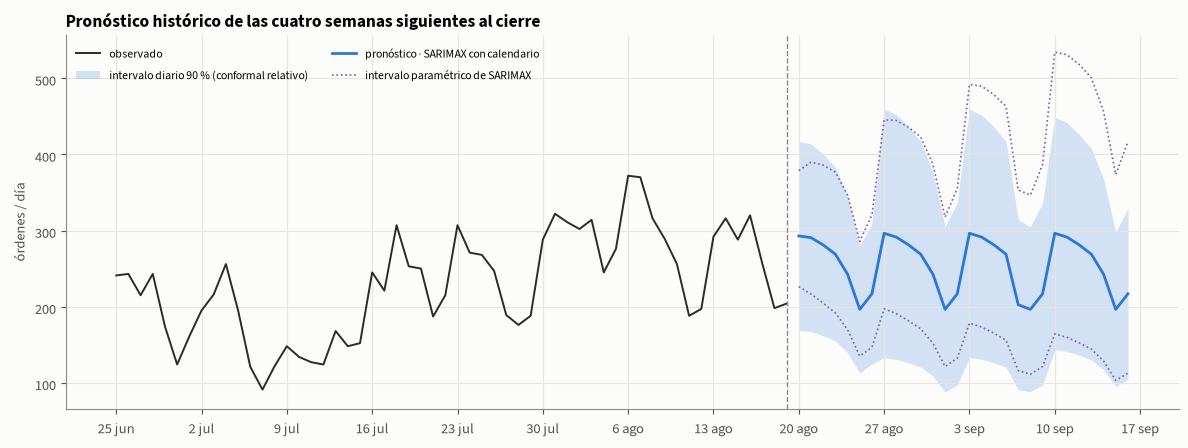

Suma de puntos a 28 días: 7,130.9 pedidos.


In [20]:
# El reajuste usa toda la historia útil; los reales futuros siguen vacíos.
origen_final=pd.Timestamp(FIN)
p_final,aj_final=predecir(ganador,y,variables,calendario,origen_final)
param_final={k:aj_final.pop(k) for k in ['inferior_param','superior_param'] if k in aj_final}
fechas_finales=pd.date_range(origen_final+pd.Timedelta(days=1),periods=HORIZONTE)
final=pd.DataFrame(dict(modelo=ganador,origen=origen_final,fecha=fechas_finales,h=np.arange(1,HORIZONTE+1),real=np.nan,pred=p_final))
final_d=aplicar_intervalos(final,cal_diaria['relativo'])
final_s=aplicar_intervalos(final,cal_semanal['relativo'],semanal=True)
exportar(final_d,'pronostico_diario_28_dias'); exportar(final_s,'pronostico_semanal')
exportar(pd.DataFrame([aj_final]),'ajuste_final')
print(f'Emisión al cierre del domingo {fecha_es(origen_final)}: del {fecha_es(fechas_finales[0])} al {fecha_es(fechas_finales[-1])}.')
# Redondeamos solo columnas numéricas para presentar; los CSV conservan precisión.
festivos_finales=calendario.set_index('fecha').festivo
vista_d=final_d[['fecha','h','pred','inferior','superior']].assign(
    dia=[DIAS[f.dayofweek] for f in final_d.fecha],festivo=final_d.fecha.map(festivos_finales))
vista_s=final_s[['semana','desde','hasta','pred','inferior','superior']].copy()
for vista in [vista_d,vista_s]:
    vista[['pred','inferior','superior']]=vista[['pred','inferior','superior']].round(1)
mostrar(vista_d,'Pronóstico diario con intervalo conformal relativo del 90 %','festivo = 1: festivo nacional conocido de antemano.')
mostrar(vista_s,'Pronóstico de totales semanales (lunes a domingo) con su propio intervalo','No es la suma de límites diarios.')
fig,ax=plt.subplots(figsize=(12,4.6))
ax.plot(y.index[-56:],y.iloc[-56:].to_numpy(),color=TINTA,lw=1.4,label='observado')
ax.fill_between(final_d.fecha,final_d.inferior,final_d.superior,color=COLOR[ganador],alpha=.2,lw=0,label='intervalo diario 90 % (conformal relativo)')
ax.plot(final_d.fecha,final_d.pred,color=COLOR[ganador],lw=2,label=f'pronóstico · {NOMBRE[ganador]}')
if param_final:
    ax.plot(fechas_finales,param_final['inferior_param'],color='#7b5ea7',ls=':',lw=1.2,label='intervalo paramétrico de SARIMAX')
    ax.plot(fechas_finales,param_final['superior_param'],color='#7b5ea7',ls=':',lw=1.2)
ax.axvline(origen_final,color=TENUE,ls='--',lw=1)
ax.set_ylabel('órdenes / día'); fechas_es(ax,'semana',1); ax.legend(loc='upper left',fontsize=8.5,ncol=2)
ax.set_title('Pronóstico histórico de las cuatro semanas siguientes al cierre')
figura('pronostico_final')
print(f'Suma de puntos a 28 días: {final.pred.sum():,.1f} pedidos.')

**Lectura**

- **Perfil semanal del pronóstico** (del 20 de agosto al 16 de septiembre de 2018): de unas 296 órdenes los lunes a unas 196 los sábados. El viernes 7 de septiembre (Independencia) baja a unas 203, frente a unas 243 de un viernes normal: el indicador de festivo actúa.
- **Totales:** unas 1.790 órdenes por semana y 7.131 en las cuatro semanas (suma de puntos).
- **Nivel:** el pronóstico (≈ 256 diarias) parte del nivel de las últimas semanas, más bajo que el pico de inicios de agosto. Sin deriva, SARIMAX no extrapola ese salto.
- **Intervalos:**
  - el conformal relativo da ±42 % del pronóstico en la primera semana y alrededor de ±55 % después;
  - el paramétrico es más estrecho al principio y se abre con el horizonte;
  - dada la cobertura de prueba (76 %), ambos deben leerse como optimistas.

**Qué implica.** Este es el entregable: un plan diario y semanal con márgenes, emitido con la misma regla que se evaluó.

## 18. Interpretar los modelos sin atribuir causalidad

**SARIMAX.** Sus coeficientes se leen directamente. Como el modelo está en `log1p`, `exp(coef) − 1` es el efecto porcentual aproximado de un indicador frente a un día sin él. Para los días de la semana, la referencia es el domingo. Se muestran los del ajuste final, con toda la historia útil.

**LightGBM.** La importancia por ganancia resume cuánto redujeron la pérdida las divisiones que usaron cada variable. Depende de variables correlacionadas y no indica que intervenir esa variable cause más ventas. Se muestra para el mejor LightGBM de selección, aunque el ganador global pertenezca a otra familia.

Ninguna de las dos lecturas es causal: describen lo que cada modelo aprendió de la historia.


■ SARIMAX_calendario ajustado hasta el último domingo: coeficientes en log y efecto %
  dia_1 = lunes … dia_6 = sábado, frente al domingo. ar/ma: dinámica de los errores; sigma2: varianza de la innovación.


,coeficiente,efecto_pct
festivo,-0.180,-16.462
carnaval,-0.342,-28.935
black_friday,1.481,339.710
post_black_friday,0.514,67.243
fin_anio,-0.602,-45.227
dia_1,0.311,36.537
dia_2,0.294,34.220
dia_3,0.259,29.584
dia_4,0.214,23.917
dia_5,0.112,11.902


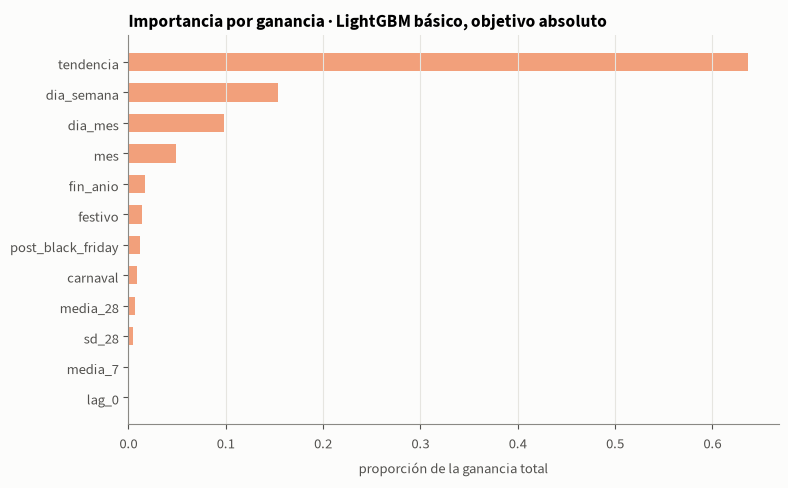

In [21]:
# Coeficientes del SARIMAX con toda la historia útil: efecto % = exp(coef) − 1.
_,detalle_final=predecir('SARIMAX_calendario',y,variables,calendario,origen_final,detalles=True)
coef=pd.Series(detalle_final['coeficientes']).rename('coeficiente').to_frame()
efecto=coef.index.str.startswith('dia_')|coef.index.isin(EVENTOS)
coef['efecto_pct']=np.where(efecto,100*np.expm1(coef.coeficiente),np.nan)
exportar(coef.reset_index(names='parametro'),'coeficientes_sarimax_final')
mostrar(coef.round(3),'SARIMAX_calendario ajustado hasta el último domingo: coeficientes en log y efecto %',
        'dia_1 = lunes … dia_6 = sábado, frente al domingo. ar/ma: dinámica de los errores; sigma2: varianza de la innovación.')
# La ganancia explica el ajuste de ML y no se interpreta como causalidad.
_,detalle_ml=predecir(mejor_ml,y,variables,calendario,origen_final,detalles=True)
importancia=pd.DataFrame(detalle_ml['importancia_gain'].items(),columns=['variable','ganancia']).sort_values('ganancia',ascending=False)
importancia['proporcion']=importancia.ganancia/importancia.ganancia.sum()
exportar(importancia,'importancia_variables')
top=importancia.head(12).sort_values('proporcion')
fig,ax=plt.subplots(figsize=(8,5))
ax.barh(top.variable,top.proporcion,color=COLOR[mejor_ml],height=.6); ax.grid(axis='y',visible=False)
ax.set_xlabel('proporción de la ganancia total'); ax.set_title(f'Importancia por ganancia · {NOMBRE[mejor_ml]}')
figura('importancia_variables')

**Lectura de la tabla de coeficientes**

- **Semana:** frente al domingo, el lunes vende ≈ 37 % más y el martes ≈ 34 %, y el efecto baja hasta el viernes (≈ +12 %); el sábado vende ≈ 9 % menos. Es el perfil de 01 §2.2, ahora estimado con toda la historia.
- **Eventos:**
  - Black Friday multiplica por ≈ 4,4 (+340 %) y sus cuatro días posteriores suman ≈ +67 %;
  - fin de año resta ≈ 45 %, un festivo ≈ 16 % y Carnaval ≈ 29 %;
  - con dos Carnavales en la historia, su efecto se acerca a lo observado en 2018.
- **Errores:** MA(1) = −0,64 y AR(1) = 0,20. La dinámica de corto plazo que 01 §2.6 anticipó se mantiene.

**Lectura del gráfico**

- **`tendencia`** (días desde el inicio de la serie) concentra cerca del 64 % de la ganancia. Le siguen el día de la semana (≈ 15 %), el día del mes y el mes. Los rezagos y las medias móviles casi no aportan.
- **El LightGBM absoluto aprende el nivel de cada período a través de `tendencia`.** Dentro del rango visto funciona, pero un árbol no extrapola: en prueba, todas las fechas futuras caen en la última hoja y el nivel queda congelado. Es el riesgo que 01 §2.1 señaló para las tendencias, y explica por qué LightGBM no supera al baseline en prueba ni sigue el salto de agosto.

**Qué implica.** En una siguiente iteración convendría retirar `tendencia` o usar un objetivo relativo a un nivel más robusto que `media_28`. No se cambia ahora, porque sería ajustar el modelo con la prueba.

## 19. Conclusiones

Las cifras se generan desde las tablas para evitar inconsistencias. La auditoría adicional (`scripts/auditar.py`) concilia las métricas mediante SQL, verifica ventanas y calendario, retira físicamente el futuro para reproducir ajustes y comprueba que los notebooks estén ejecutados sin errores.

In [22]:
# Las conclusiones se generan desde tablas para evitar cifras inconsistentes.
ms=m_sel.set_index('modelo'); mt=m_test.set_index('modelo')
cd=cov_d.set_index('metodo_intervalo').loc['relativo']
cs=cov_s.set_index('metodo_intervalo').loc['relativo']
cm=cov_metodos.set_index('metodo_intervalo')
resumen=dict(inicio=INICIO,fin=FIN,ganador=ganador,mejor_ml=mejor_ml,
    MAE_seleccion=float(ms.loc[ganador,'MAE']),MAE_prueba=float(mt.loc[ganador,'MAE']),
    MAE_estacional_seleccion=float(ms.loc['Estacional_7','MAE']),
    MAE_estacional_prueba=float(mt.loc['Estacional_7','MAE']),
    mejor_prueba=m_test.iloc[0].modelo,cobertura_diaria=float(cd.cobertura),
    cubiertos_diarios=int(cd.cubiertos),n_diarios=int(cd.n),
    cobertura_semanal=float(cs.cobertura),cubiertos_semanales=int(cs.cubiertos),n_semanales=int(cs.n),
    cobertura_parametrica=float(cm.loc['parametrico_sarimax','cobertura']),
    cobertura_conformal_ml=float(cm.loc['conformal_ml','cobertura']),
    total_puntos_28_dias=float(final.pred.sum()),n_dias=len(serie),total_pedidos=int(serie.y.sum()),
    interpretacion='Retrospectiva; los datos de prueba ya eran conocidos. Sin garantía de cobertura futura.')
(ROOT/'resultados/resumen.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown(f"""**Selección:** {ganador}, MAE {resumen['MAE_seleccion']:.2f} pedidos frente a {resumen['MAE_estacional_seleccion']:.2f} de Estacional_7.

**Prueba:** MAE {resumen['MAE_prueba']:.2f}; Estacional_7 {resumen['MAE_estacional_prueba']:.2f}; mejor MAE observado: {resumen['mejor_prueba']}.

**Incertidumbre (90 % nominal):** conformal relativo {cd.cobertura:.1%} diario ({int(cd.cubiertos)}/{int(cd.n)}) y {cs.cobertura:.1%} semanal ({int(cs.cubiertos)}/{int(cs.n)});
paramétrico de SARIMAX {resumen['cobertura_parametrica']:.1%}; conformal de {mejor_ml} {resumen['cobertura_conformal_ml']:.1%}.

**Pronóstico final:** suma de puntos {final.pred.sum():,.1f} pedidos; se lee junto a sus intervalos."""))
if cd.cobertura < NIVEL:
    print('El intervalo principal NO alcanzó el 90 % nominal en prueba: sus límites finales son experimentales.')
con.close()

**Selección:** SARIMAX_calendario, MAE 42.20 pedidos frente a 56.39 de Estacional_7.

**Prueba:** MAE 61.50; Estacional_7 66.42; mejor MAE observado: ETS_amortiguado.

**Incertidumbre (90 % nominal):** conformal relativo 76.4% diario (107/140) y 80.0% semanal (16/20);
paramétrico de SARIMAX 73.6%; conformal de LGBM_base_absoluto 70.7%.

**Pronóstico final:** suma de puntos 7,130.9 pedidos; se lee junto a sus intervalos.

El intervalo principal NO alcanzó el 90 % nominal en prueba: sus límites finales son experimentales.


### Respuesta a cada punto del taller

1. **Baselines.** Ingenuo (último valor) y Estacional_7 (mismo día de la semana anterior) se evalúan en todas las etapas. Estacional_7 es una vara exigente: captura la semana sin estimar nada.
2. **Modelos.**
   - El estadístico principal es **SARIMAX_calendario**: `log1p`, ARIMA(1,1,1), seis indicadores de día y cinco de eventos; también se evalúa ETS sobre log. Ambos son recursivos.
   - El de ML es **LightGBM directo global**, con rezagos, medias móviles y calendario construidos en SQL sin mirar al futuro.
   - SARIMAX_calendario gana la selección (MAE 42,2; 25 % mejor que Estacional_7) y mantiene la ventaja en prueba (61,5 frente a 66,4).
3. **Métricas por horizonte.**
   - MAE, RMSE, MAPE y sMAPE se informan por h, por semana del horizonte y por origen.
   - En selección, el MAE del ganador crece de unos 24 pedidos en h = 1 a unos 48 en promedio en h = 22–28, y supera a ambos baselines en las cuatro semanas.
   - En prueba la ventaja se concentra en la primera semana.
4. **Incertidumbre.**
   - Se comparan el intervalo paramétrico de SARIMAX y tres intervalos conformales calibrados en una etapa reservada.
   - Ninguno alcanza el 90 % nominal en prueba (principal: 76 % diario y 80 % semanal), porque la prueba contiene un valle y un salto de nivel que la calibración no conocía.
   - Se informan como límites experimentales, no como márgenes validados.

### Coherencia con la exploración

Cada decisión de forma —escala log, `d = 1`, semana determinística, eventos modelados frente a marcados— viene de 01 y se fijó antes de ver la selección. La evaluación la respalda:
- modelar eventos reduce el MAE en 9 pedidos;
- ETS y SARIMAX, construidos sobre el mismo diagnóstico, son los mejores en prueba;
- la huelga marcada explica la amplitud de los intervalos.

También muestra límites honestos:
- un indicador con una sola ocurrencia (Black Friday, Carnaval) no garantiza su magnitud;
- la caída previa a Navidad sigue sin modelarse;
- el LightGBM absoluto depende de una variable de tendencia que no extrapola.

### Trabajo futuro

- Recalibrar los intervalos cada semana con errores recientes.
- Incorporar variables de campañas comerciales que expliquen saltos como el de agosto.
- Retirar `tendencia` del LightGBM.
- Validar el indicador de pre-Navidad con un segundo diciembre.

## Preguntas para defender el ejercicio

1. **¿Qué se predice?** Órdenes compradas por día durante los 28 días siguientes al cierre de un domingo.
2. **¿Por qué no barajar días?** Porque el entrenamiento conocería el futuro del ejemplo evaluado.
3. **¿Por qué filtrar la fecha objetivo?** Una fila de origen pasado puede tener una etiqueta todavía futura.
4. **¿Recursiva o directa?** SARIMAX y ETS propagan su estado (recursiva); LightGBM aprende cada horizonte directamente desde el origen, sin reinyectar predicciones.
5. **¿Por qué dos baselines?** Para saber cuánto valor añade la complejidad frente a reglas comprensibles; Estacional_7 ya captura la semana.
6. **¿Qué significa MAE = 40?** Un error absoluto promedio de 40 pedidos por par evaluado; no un máximo.
7. **¿Paramétrico o conformal?** El paramétrico depende de que el modelo esté bien especificado; el conformal depende de que los errores futuros se parezcan a los de calibración. Ninguno garantiza cobertura ante un cambio de régimen.
8. **¿Se puede sumar un intervalo diario?** No para atribuir automáticamente la misma cobertura al total semanal.
9. **¿Por qué la huelga no tiene indicador?** Porque no se conocía con cuatro semanas de antelación; dárselo al modelo sería fuga de información.
10. **¿El modelo ganador sirve siempre?** Su rendimiento es específico de este protocolo y período; hace falta monitoreo y reevaluación.